## Part A — Data Understanding

### A0. Persiapan & Konfigurasi
Impor seluruh library yang digunakan di notebook, definisi fungsi utilitas bersama, konfigurasi path berkas XML/DTD di luar repositori, serta validasi keberadaan berkas dan header `DOCTYPE`.

In [1]:
# A0 - Imports, helper functions, path & DTD validation
import hashlib
import json
import os
import random
import re
import time
import unicodedata
from collections import Counter
from pathlib import Path

import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
from IPython.display import display
from lxml import etree

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 150)

# Konfigurasi path (dapat di-override lewat environment variable DBLP_XML_PATH)
XML_PATH = Path(
    os.environ.get(
        "DBLP_XML_PATH",
        r"C:\Users\Mark\Documents\ITB\DataMining\TugasKelompok\dblp-2025-12-01.xml",
    )
)
OUT_DIR = Path("data")
OUT_DIR.mkdir(exist_ok=True)

if not XML_PATH.is_file():
    raise FileNotFoundError(f"XML tidak ditemukan: {XML_PATH}\nSet DBLP_XML_PATH atau ubah XML_PATH.")

with open(XML_PATH, "rb") as f:
    head = f.read(4096).decode("latin-1")

m_doc = re.search(r'<!DOCTYPE\s+(\w+)\s+SYSTEM\s+"([^"]+)"', head)
if m_doc is None:
    raise RuntimeError("Deklarasi DOCTYPE ... SYSTEM tidak ditemukan pada 4096 byte pertama.")

ROOT_TAG = m_doc.group(1)
DTD_NAME = m_doc.group(2)
if Path(DTD_NAME).name != DTD_NAME:
    raise RuntimeError(f"Nama DTD pada header bukan nama berkas langsung: {DTD_NAME!r}")

DTD_PATH = XML_PATH.parent / DTD_NAME
if not DTD_PATH.is_file():
    raise FileNotFoundError(f"XML memerlukan {DTD_NAME}, tetapi tidak ditemukan di {XML_PATH.parent}")

GENERIC_TITLES = {
    "preface", "foreword", "front matter", "table of contents", "author index",
    "welcome", "committee", "keynote", "keynote talk", "invited talk",
    "panel", "tutorial", "posters", "demos", "session overview",
}

def norm_str(s):
    """Normalisasi Unicode NFC, merapikan spasi berlebih menjadi satu spasi, dan strip."""
    return "" if s is None else " ".join(unicodedata.normalize("NFC", str(s)).split())

def normalize_title_key(series):
    """Normalisasi judul sementara khusus untuk pencocokan duplikat."""
    return (
        series.fillna("")
        .str.normalize("NFC")
        .str.casefold()
        .str.replace(r"[\W_]+", " ", regex=True)
        .str.strip()
    )

def file_sha256(path, block=1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while chunk := f.read(block):
            h.update(chunk)
    return h.hexdigest()

print(f"XML : {XML_PATH} ({XML_PATH.stat().st_size:,} bytes)")
print(f"DTD : {DTD_PATH} (dari header XML)")

XML : C:\Users\Mark\Documents\ITB\DataMining\TugasKelompok\dblp-2025-12-01.xml (4,939,110,596 bytes)
DTD : C:\Users\Mark\Documents\ITB\DataMining\TugasKelompok\dblp-2023-06-28.dtd (dari header XML)


### A1. Metadata & Provenance Dataset
Mencatat asal usul dataset DBLP, tanggal rilis snapshot, tanggal pengambilan, DOI resmi dari Dagstuhl, serta verifikasi integritas berkas melalui checksum SHA-256 (XML dan DTD) dan MD5 (arsip `.xml.gz` terhadap nilai resmi di situs penerbit).

In [2]:
# A1 - Dataset provenance & checksum verification
t0 = time.time()
xml_sha = file_sha256(XML_PATH)
dtd_sha = file_sha256(DTD_PATH)
print(f"SHA-256 selesai dalam {time.time() - t0:.1f}s")

GZ_PATH = XML_PATH.with_name(XML_PATH.name + ".gz")
SITE_MD5_GZ = "bccb40fc73f6603ec153a6ff74f39eb9"

if GZ_PATH.is_file():
    h_md5 = hashlib.md5()
    with open(GZ_PATH, "rb") as f:
        while chunk := f.read(1024 * 1024):
            h_md5.update(chunk)
    gz_md5 = h_md5.hexdigest()
    gz_status = "MATCH" if gz_md5 == SITE_MD5_GZ else "DIFF"
    gz_info = f"{gz_md5} ({gz_status} dengan situs penerbit)"
else:
    gz_info = f"{SITE_MD5_GZ} (berkas .gz lokal tidak tersedia)"

DOI_SNAPSHOT = "10.4230/dblp.xml.2025-12-01"
DOI_DTD = "10.4230/dblp.xml.dtd.2023-06-28"
date_in_name = re.search(r"\d{4}-\d{2}-\d{2}", XML_PATH.name).group(0)
date_in_doi = re.search(r"\d{4}-\d{2}-\d{2}", DOI_SNAPSHOT).group(0)
assert date_in_name == date_in_doi, "Tanggal pada nama berkas dan string DOI tidak cocok"

prov_rows = [
    ("Ukuran berkas XML (byte)", f"{XML_PATH.stat().st_size:,}", "Dihitung dari berkas", "Dihitung"),
    ("SHA-256 XML", xml_sha, "Dihitung dari berkas", "Dihitung"),
    ("SHA-256 DTD", dtd_sha, "Dihitung dari berkas", "Dihitung"),
    ("Nama DTD", DTD_NAME, "Header XML", "Dibaca dari berkas"),
    ("Rilis", "Monthly Snapshot XML Release of December 2025", "Halaman DOI", "Manual"),
    ("Tanggal snapshot", date_in_name, "Nama berkas & DOI", "Disimpulkan dari penamaan"),
    ("Penerbit", "Schloss Dagstuhl – Leibniz-Zentrum für Informatik", "Halaman DOI", "Manual"),
    ("DOI snapshot", DOI_SNAPSHOT, "Halaman DOI", "Manual"),
    ("DOI DTD", DOI_DTD, "Halaman Dagstuhl", "Manual"),
    ("Tanggal pengambilan", "2026-11-16", "Catatan unduhan tim", "Manual"),
    ("MD5 berkas .gz", gz_info, "Dihitung vs checksum penerbit", "Dihitung + Manual"),
]
prov = pd.DataFrame(prov_rows, columns=["fakta", "nilai", "sumber", "jenis"])
with pd.option_context("display.max_colwidth", None):
    display(prov)

SHA-256 selesai dalam 17.9s


,fakta,nilai,sumber,jenis
0,Ukuran berkas XML (byte),"4,939,110,596",Dihitung dari berkas,Dihitung
1,SHA-256 XML,0f3dbcbd332674bd2e292395367888d1d39dec2a497d08d5c08b1d8298907d3e,Dihitung dari berkas,Dihitung
2,SHA-256 DTD,2d864498f9eef9298662df11e3874171ff24cd4a21ab5974f1369c90acdb1ef6,Dihitung dari berkas,Dihitung
3,Nama DTD,dblp-2023-06-28.dtd,Header XML,Dibaca dari berkas
4,Rilis,Monthly Snapshot XML Release of December 2025,Halaman DOI,Manual
5,Tanggal snapshot,2025-12-01,Nama berkas & DOI,Disimpulkan dari penamaan
6,Penerbit,Schloss Dagstuhl – Leibniz-Zentrum für Informatik,Halaman DOI,Manual
7,DOI snapshot,10.4230/dblp.xml.2025-12-01,Halaman DOI,Manual
8,DOI DTD,10.4230/dblp.xml.dtd.2023-06-28,Halaman Dagstuhl,Manual
9,Tanggal pengambilan,2026-11-16,Catatan unduhan tim,Manual


### A2.1 Inspeksi DTD, Profil Empiris XML & Tipe Record
Memeriksa deklarasi skema pada berkas DTD (`ELEMENT`, `ATTLIST`, dan entitas parameter `%field;`), mencocokkannya dengan hasil *streaming profile* seluruh record pada XML (`data/dblp_profile.json`), serta merangkum seluruh tipe record beserta deskripsinya berdasarkan dokumentasi resmi FAQ DBLP (`https://dblp.org/faq/16154937.html`).

In [3]:
# A2.1 - DTD parsing, empirical XML profile (cached JSON), cross-check, and record types
RUN_PROFILE = False      # Ubah ke True hanya jika ingin menghitung ulang profil dari XML 4,9 GB
PROFILE_LIMIT = None     # None = full run
PROFILE_JSON = OUT_DIR / "dblp_profile.json"

# 1) Parse deklarasi DTD
dtd_text = DTD_PATH.read_text(encoding="latin-1")
ent_decls = dict(re.findall(r'<!ENTITY\s+%\s+(\S+)\s+"([^"]*)"\s*>', dtd_text, re.S))

def expand_entities(text, depth=5):
    for _ in range(depth):
        new = re.sub(r"%([\w.-]+);", lambda m: ent_decls.get(m.group(1), m.group(0)), text)
        if new == text:
            break
        text = new
    return text

def extract_declared_names(decl, own_name):
    toks = re.findall(r"[A-Za-z][\w.-]*", expand_entities(decl))
    return sorted({t for t in toks if t not in {"ELEMENT", "PCDATA", "EMPTY", "ANY", own_name}})

root_decl = re.search(rf"<!ELEMENT\s+{ROOT_TAG}\b[^>]*>", dtd_text, re.S).group(0)
inproc_decl = re.search(r"<!ELEMENT\s+inproceedings\b[^>]*>", dtd_text, re.S).group(0)
DTD_REC_TAGS = extract_declared_names(root_decl, ROOT_TAG)
DTD_INPROC_CHILDREN = extract_declared_names(inproc_decl, "inproceedings")

# 2) Muat atau jalankan streaming profile XML
def counter_to_rows(counter):
    return [list(k) + [v] for k, v in sorted(counter.items(), key=lambda kv: str(kv[0]))]

if not RUN_PROFILE and PROFILE_JSON.exists():
    prof = json.loads(PROFILE_JSON.read_text(encoding="utf-8"))
    assert prof["full_run"] and prof["xml_sha256"] == xml_sha, "Profil JSON tidak sesuai dengan berkas XML saat ini"
    print(f"Memuat profil XML tersimpan: {PROFILE_JSON} ({prof['records_seen']:,} record)")
else:
    type_n, attr_n, child_n, child_max = Counter(), Counter(), Counter(), Counter()
    nested_n, key_parts, publtype_v = Counter(), Counter(), Counter()
    t0, seen = time.time(), 0

    ctx = etree.iterparse(
        str(XML_PATH), events=("end",), load_dtd=True, resolve_entities=True, huge_tree=True
    )
    for _, el in ctx:
        parent = el.getparent()
        if parent is None or parent.getparent() is not None:
            continue
        rtype = el.tag
        type_n[rtype] += 1
        for a in el.attrib:
            attr_n[(rtype, a)] += 1
        if (pt := el.get("publtype")) is not None:
            publtype_v[(rtype, pt)] += 1
        k = el.get("key")
        key_parts[(rtype, len(k.split("/")) if k else 0)] += 1

        kids = [c for c in el if isinstance(c.tag, str)]
        for tag, n in Counter(c.tag for c in kids).items():
            child_n[(rtype, tag)] += 1
            if n > child_max[(rtype, tag)]:
                child_max[(rtype, tag)] = n
        for c in kids:
            for d in c.iterdescendants():
                if isinstance(d.tag, str):
                    nested_n[(rtype, c.tag, d.tag)] += 1

        el.clear()
        while el.getprevious() is not None:
            del parent[0]
        seen += 1
        if seen % 1_000_000 == 0:
            print(f"  {seen:,} record ({time.time() - t0:.0f}s)")
        if PROFILE_LIMIT and seen >= PROFILE_LIMIT:
            break

    prof = {
        "xml_sha256": xml_sha,
        "dtd": DTD_NAME,
        "profile_limit": PROFILE_LIMIT,
        "full_run": PROFILE_LIMIT is None,
        "records_seen": seen,
        "profiled_at": time.strftime("%Y-%m-%d %H:%M:%S"),
        "type_counts": dict(type_n),
        "attr_counts": counter_to_rows(attr_n),
        "child_counts": counter_to_rows(child_n),
        "child_max": counter_to_rows(child_max),
        "nested_counts": counter_to_rows(nested_n),
        "key_parts": counter_to_rows(key_parts),
        "publtype_values": counter_to_rows(publtype_v),
    }
    tmp = PROFILE_JSON.with_name(PROFILE_JSON.name + ".tmp")
    tmp.write_text(json.dumps(prof, indent=1, ensure_ascii=False), encoding="utf-8")
    tmp.replace(PROFILE_JSON)
    print(f"Profil disimpan ke {PROFILE_JSON} ({seen:,} record dalam {time.time() - t0:.0f}s)")

# 3) Pemeriksaan silang tag record DTD vs data aktual
data_tags, dtd_tags = set(prof["type_counts"]), set(DTD_REC_TAGS)
print("Tag di data tetapi tidak di DTD:", sorted(data_tags - dtd_tags) or "tidak ada")
print("Tag di DTD tetapi tidak di data:", sorted(dtd_tags - data_tags) or "tidak ada")

# 4) Tabel tipe record beserta deskripsi FAQ DBLP
RECORD_DESC = {
    "article": "Artikel dari jurnal atau majalah.",
    "inproceedings": "Makalah dalam proceedings konferensi atau workshop.",
    "proceedings": "Volume proceedings sebuah konferensi atau workshop.",
    "book": "Monograf karya penulis, atau kumpulan artikel yang disunting.",
    "incollection": "Bagian atau bab dalam sebuah monograf.",
    "phdthesis": "Disertasi doktor (PhD).",
    "mastersthesis": "Tesis magister; menurut FAQ jumlahnya sangat sedikit.",
    "www": "Halaman web; menurut FAQ hanya sedikit (lihat catatan record person).",
    "data": "Ada di DTD, tetapi tidak dijelaskan di halaman FAQ yang kami baca.",
    "person": "Ada di DTD; FAQ hanya menyebut bahwa record person dijelaskan di halaman terpisah. Tidak ada record bertipe ini di data.",
}

counts = prof["type_counts"]
total_rec = sum(counts.values())
type_rows = [
    (t, RECORD_DESC[t], n, round(100 * n / total_rec, 2))
    for t, n in sorted(counts.items(), key=lambda kv: -kv[1])
]
type_rows += [(t, RECORD_DESC[t], 0, 0.0) for t in RECORD_DESC if t not in counts]
types_tbl = pd.DataFrame(type_rows, columns=["tipe", "deskripsi", "jumlah_record", "persen"])
types_tbl.loc[len(types_tbl)] = ["TOTAL", "", total_rec, 100.0]
with pd.option_context("display.max_colwidth", None):
    display(types_tbl)

  1,000,000 record (58s)
  2,000,000 record (116s)
  3,000,000 record (176s)
  4,000,000 record (235s)
  5,000,000 record (263s)
  6,000,000 record (289s)
  7,000,000 record (315s)
  8,000,000 record (347s)
  9,000,000 record (418s)
  10,000,000 record (485s)
  11,000,000 record (549s)
  12,000,000 record (613s)
Profil disimpan ke data\dblp_profile.json (12,169,828 record dalam 622s)
Tag di data tetapi tidak di DTD: tidak ada
Tag di DTD tetapi tidak di data: ['person']


,tipe,deskripsi,jumlah_record,persen
0,article,Artikel dari jurnal atau majalah.,4101061,33.70
1,www,Halaman web; menurut FAQ hanya sedikit (lihat catatan record person).,3955829,32.51
2,inproceedings,Makalah dalam proceedings konferensi atau workshop.,3788716,31.13
3,phdthesis,Disertasi doktor (PhD).,149054,1.22
4,incollection,Bagian atau bab dalam sebuah monograf.,70988,0.58
5,proceedings,Volume proceedings sebuah konferensi atau workshop.,63072,0.52
6,book,"Monograf karya penulis, atau kumpulan artikel yang disunting.",21291,0.17
7,data,"Ada di DTD, tetapi tidak dijelaskan di halaman FAQ yang kami baca.",19790,0.16
8,mastersthesis,Tesis magister; menurut FAQ jumlahnya sangat sedikit.,27,0.00
9,person,Ada di DTD; FAQ hanya menyebut bahwa record person dijelaskan di halaman terpisah. Tidak ada record bertipe ini di data.,0,0.00


### A2.2 Profil Elemen `inproceedings` & Keputusan Skema Ekstraksi
Memeriksa kemunculan setiap elemen anak dan atribut pada record `inproceedings` (bentuk *scalar* vs *list*, persentase kelengkapan, serta keberadaan di DTD) untuk menetapkan kolom yang diekstrak ke tabel mentah.

In [4]:
# A2.2 - inproceedings child profile & schema decision table
n_in = prof["type_counts"]["inproceedings"]
cnt = {c: n for t, c, n in prof["child_counts"] if t == "inproceedings"}
mx = {c: n for t, c, n in prof["child_max"] if t == "inproceedings"}

SCHEMA_REASONS = {
    "author": "dibutuhkan untuk hitungan author unik (Task 1, 2) dan transaksi (Task 3)",
    "title": "pemeriksaan duplikat metadata",
    "year": "filter periode 2015–2025 dan analisis tren tahunan",
    "booktitle": "nama tampilan venue/konferensi",
    "crossref": "tautan ke record proceedings dan validasi tahun (hanya nilai pertama)",
}

fields = sorted(set(DTD_INPROC_CHILDREN) | set(cnt))
field_tbl = pd.DataFrame({
    "field": fields,
    "records_with": [cnt.get(f, 0) for f in fields],
    "pct_records": [round(100 * cnt.get(f, 0) / n_in, 2) for f in fields],
    "max_per_record": [mx.get(f, 0) for f in fields],
})
field_tbl["bentuk"] = field_tbl["max_per_record"].map(
    lambda m: "absent" if m == 0 else ("list" if m > 1 else "scalar")
)
field_tbl["in_DTD"] = field_tbl["field"].isin(DTD_INPROC_CHILDREN)
field_tbl["dipakai"] = field_tbl["field"].map(lambda f: "ya" if f in SCHEMA_REASONS else "tidak")
field_tbl["alasan"] = field_tbl["field"].map(
    lambda f: SCHEMA_REASONS.get(f, "tidak dipakai task mana pun")
)

with pd.option_context("display.max_colwidth", None):
    display(field_tbl.sort_values(["dipakai", "records_with"], ascending=[False, False]).reset_index(drop=True))

,field,records_with,pct_records,max_per_record,bentuk,in_DTD,dipakai,alasan
0,title,3788716,100.00,1,scalar,True,ya,pemeriksaan duplikat metadata
1,year,3788716,100.00,1,scalar,True,ya,filter periode 2015–2025 dan analisis tren tahunan
2,booktitle,3788697,100.00,1,scalar,True,ya,nama tampilan venue/konferensi
3,crossref,3786117,99.93,2,list,True,ya,tautan ke record proceedings dan validasi tahun (hanya nilai pertama)
4,author,3783358,99.86,279,list,True,ya,"dibutuhkan untuk hitungan author unik (Task 1, 2) dan transaksi (Task 3)"
5,url,3788716,100.00,1,scalar,True,tidak,tidak dipakai task mana pun
6,ee,3651558,96.38,7,list,True,tidak,tidak dipakai task mana pun
7,pages,3582752,94.56,1,scalar,True,tidak,tidak dipakai task mana pun
8,stream,89284,2.36,1,scalar,True,tidak,tidak dipakai task mana pun
9,cdrom,8482,0.22,2,list,True,tidak,tidak dipakai task mana pun


### A3. Ekstraksi Data Mentah (`inproceedings`, 2015–2025) & Verifikasi
Melakukan satu kali *streaming pass* pada berkas XML untuk menyaring record bertipe `inproceedings` dengan tahun `2015`–`2025` ke format Parquet (`data/raw_inproceedings.parquet`) dan menyimpan ringkasan jumlah ke `data/raw_counts.json`. Penulisan dilakukan secara atomik melalui berkas `.tmp`, dan proses otomatis dilewati jika berkas hasil ekstraksi sudah tersedia.

In [7]:
# A3 - Extraction config, streaming parser, and artifact verification
YEAR_MIN, YEAR_MAX = 2015, 2025
CHUNK_ROWS = 100_000
MAX_RECORDS = None
RUN_EXTRACTION = False  # Ubah ke True hanya jika ingin mengekstrak ulang dari XML

TAG = "_test" if MAX_RECORDS else ""
RAW_PARQUET = OUT_DIR / f"raw_inproceedings{TAG}.parquet"
COUNTS_JSON = OUT_DIR / f"raw_counts{TAG}.json"
REC_TAGS = set(DTD_REC_TAGS)

SCHEMA = pa.schema([
    ("paper_key", pa.string()),
    ("authors", pa.list_(pa.string())),
    ("title", pa.string()),
    ("year_raw", pa.string()),
    ("booktitle", pa.string()),
    ("crossref", pa.string()),
    ("key_prefix", pa.string()),
    ("venue_key", pa.string()),
])

def text_of(el):
    """Mengambil seluruh teks di dalam elemen termasuk tag inline seperti <i> atau <sup>."""
    return "".join(el.itertext()).strip() if el is not None else None

def parse_inproceedings(el):
    key = el.get("key")
    parts = key.split("/") if key else []
    return {
        "paper_key": key,
        "authors": [text_of(a) for a in el.findall("author")],
        "title": text_of(el.find("title")),
        "year_raw": text_of(el.find("year")),
        "booktitle": text_of(el.find("booktitle")),
        "crossref": text_of(el.find("crossref")),
        "key_prefix": parts[0] if parts else None,
        "venue_key": parts[1] if len(parts) >= 3 else None,
    }

def run_extraction():
    type_counts, year_counts, prefix_counts = Counter(), Counter(), Counter()
    total = kept = bad_year = 0
    buffer = []
    t0 = time.time()

    tmp = RAW_PARQUET.with_name(RAW_PARQUET.name + ".tmp")
    writer = pq.ParquetWriter(tmp, SCHEMA)

    def flush():
        nonlocal buffer
        if buffer:
            writer.write_table(pa.Table.from_pylist(buffer, schema=SCHEMA))
            buffer = []

    try:
        ctx = etree.iterparse(
            str(XML_PATH), events=("end",), load_dtd=True, resolve_entities=True, huge_tree=True
        )
        for _, el in ctx:
            if el.tag not in REC_TAGS:
                continue
            total += 1
            type_counts[el.tag] += 1

            if el.tag == "inproceedings":
                rec = parse_inproceedings(el)
                prefix_counts[str(rec["key_prefix"])] += 1
                y = rec["year_raw"]
                if y and y.isdigit():
                    year_counts[y] += 1
                    if YEAR_MIN <= int(y) <= YEAR_MAX:
                        buffer.append(rec)
                        kept += 1
                        if len(buffer) >= CHUNK_ROWS:
                            flush()
                else:
                    bad_year += 1

            el.clear()
            while el.getprevious() is not None:
                del el.getparent()[0]

            if total % 1_000_000 == 0:
                print(f"  {total:,} record diproses, {kept:,} disimpan ({time.time() - t0:.0f}s)")
            if MAX_RECORDS and total >= MAX_RECORDS:
                break
        flush()
    finally:
        writer.close()

    tmp.replace(RAW_PARQUET)
    meta_out = {
        "snapshot": XML_PATH.stem,
        "dtd": DTD_PATH.name,
        "xml_size_bytes": XML_PATH.stat().st_size,
        "xml_sha256": xml_sha,
        "year_filter": [YEAR_MIN, YEAR_MAX],
        "columns": SCHEMA.names,
        "extracted_at": time.strftime("%Y-%m-%d %H:%M:%S"),
        "elapsed_seconds": round(time.time() - t0, 1),
        "total_records": total,
        "record_type_counts": dict(type_counts),
        "inproceedings_all_years_by_year": dict(sorted(year_counts.items())),
        "inproceedings_by_key_prefix": dict(prefix_counts),
        "inproceedings_missing_or_invalid_year": bad_year,
        "rows_kept": kept,
    }
    COUNTS_JSON.write_text(json.dumps(meta_out, indent=2), encoding="utf-8")
    print(f"Selesai: {total:,} record, {kept:,} baris disimpan ({meta_out['elapsed_seconds']}s)")

if not RUN_EXTRACTION:
    print("Ekstraksi dilewati (RUN_EXTRACTION = False); memverifikasi berkas yang sudah ada.")
elif RAW_PARQUET.exists() or COUNTS_JSON.exists():
    raise FileExistsError(f"{RAW_PARQUET} atau {COUNTS_JSON} sudah ada. Hapus manual jika ingin menimpa.")
else:
    run_extraction()

# Verifikasi konsistensi artefak ekstraksi
for p in (RAW_PARQUET, COUNTS_JSON):
    assert p.exists(), f"Berkas tidak ditemukan: {p}"

meta = json.loads(COUNTS_JSON.read_text(encoding="utf-8"))
pf = pq.ParquetFile(RAW_PARQUET)

checks_a3 = {
    "nama kolom parquet == SCHEMA": pf.schema_arrow.names == SCHEMA.names,
    "jumlah baris parquet == rows_kept (JSON)": pf.metadata.num_rows == meta["rows_kept"],
    "filter tahun JSON == konfigurasi": meta["year_filter"] == [YEAR_MIN, YEAR_MAX],
    "nama DTD JSON == header XML": meta["dtd"] == DTD_NAME,
    "ukuran XML JSON == berkas XML": meta["xml_size_bytes"] == XML_PATH.stat().st_size,
    "hitungan tipe record == profil independen": meta["record_type_counts"] == prof["type_counts"],
    "total record == profil records_seen": meta["total_records"] == prof["records_seen"],
}
for name, ok in checks_a3.items():
    print("PASS" if ok else "FAIL", "-", name)
assert all(checks_a3.values()), "Verifikasi A3 gagal!" 

Ekstraksi dilewati (RUN_EXTRACTION = False); memverifikasi berkas yang sudah ada.
PASS - nama kolom parquet == SCHEMA
PASS - jumlah baris parquet == rows_kept (JSON)
PASS - filter tahun JSON == konfigurasi
PASS - nama DTD JSON == header XML
PASS - ukuran XML JSON == berkas XML
PASS - hitungan tipe record == profil independen
PASS - total record == profil records_seen


### A4. Gambaran Dataset Mentah & Pemeriksaan Konsistensi
Memeriksa alur penyaringan (*funnel*) dari seluruh XML hingga parquet mentah, distribusi publikasi per tahun (`2015`–`2025`), sebaran `key_prefix`, rasio baris paper terhadap total entri *author*, serta memperbarui jumlah record pada tabel *provenance*.

Catatan observasi: publikasi tahun `2025` (`106.389`) berjumlah sekitar separuh tahun `2024` (`207.834`) karena snapshot diambil pada Desember 2025 dan indeksasi DBLP masih berjalan; terdapat pula `23` record bertahun `2026` di luar jendela analisis, serta penurunan `-9,0%` pada tahun `2020` dibandingkan `2019`.

In [8]:
# A4 - Dataset overview, consistency checks, and provenance count update
raw = pd.read_parquet(RAW_PARQUET)

yrs_all = {int(y): n for y, n in meta["inproceedings_all_years_by_year"].items()}
n_total = meta["total_records"]
n_in = meta["record_type_counts"]["inproceedings"]
n_bad = meta["inproceedings_missing_or_invalid_year"]
n_pre = sum(n for y, n in yrs_all.items() if y < YEAR_MIN)
n_post = sum(n for y, n in yrs_all.items() if y > YEAR_MAX)
n_win = sum(n for y, n in yrs_all.items() if YEAR_MIN <= y <= YEAR_MAX)

# 1) Funnel ekstraksi
funnel_ext = pd.DataFrame(
    [
        ("Semua record di XML", n_total, 0),
        ("Hanya tipe inproceedings", n_in, n_total - n_in),
        ("Tahun valid (angka)", n_in - n_bad, n_bad),
        (f"Tahun >= {YEAR_MIN}", n_in - n_bad - n_pre, n_pre),
        (f"Tahun <= {YEAR_MAX} (parquet mentah)", n_win, n_post),
    ],
    columns=["langkah", "jumlah_setelah", "dibuang"],
)
funnel_ext["persen_dari_inproceedings"] = (funnel_ext["jumlah_setelah"] / n_in * 100).round(2)
display(funnel_ext)

# 2) Distribusi tahunan dan key_prefix
yr = raw["year_raw"].astype(int).value_counts().sort_index()
yr_tbl = yr.rename("jumlah").to_frame()
yr_tbl["perubahan_%"] = (yr.pct_change() * 100).round(1)
display(yr_tbl)

pref_all = pd.Series(meta["inproceedings_by_key_prefix"]).rename("semua_tahun")
pref_win = raw["key_prefix"].value_counts().rename("2015-2025")
display(pd.concat([pref_all, pref_win], axis=1).fillna(0).astype("int64"))

# 3) Pemeriksaan konsistensi & unit penghitungan paper vs entri author
in_win_json = {y: n for y, n in yrs_all.items() if YEAR_MIN <= y <= YEAR_MAX}
checks_a4 = {
    "jumlah tipe record == total_records": sum(meta["record_type_counts"].values()) == n_total,
    "jumlah key_prefix == inproceedings": sum(meta["inproceedings_by_key_prefix"].values()) == n_in,
    "hitungan per tahun + invalid == inproceedings": sum(yrs_all.values()) + n_bad == n_in,
    "baris parquet == rows_kept": len(raw) == meta["rows_kept"],
    "distribusi tahun parquet == JSON": raw["year_raw"].astype(int).value_counts().to_dict() == in_win_json,
    "paper_key tidak null dan unik": bool(raw["paper_key"].notna().all() and raw["paper_key"].is_unique),
}
for name, ok in checks_a4.items():
    print("PASS" if ok else "FAIL", "-", name)
assert all(checks_a4.values()), "Verifikasi A4 gagal!"

n_entries = int(raw["authors"].map(len).sum())
print(
    f"\nUnit paper vs entri author: {len(raw):,} baris paper vs {n_entries:,} entri author "
    f"({n_entries / len(raw):.2f} author/paper); daftar author kosong = {int(raw['authors'].map(len).eq(0).sum()):,} baris."
)

# Perbarui tabel provenance dengan angka record dari ekstraksi
prov = pd.concat(
    [
        prov,
        pd.DataFrame(
            [
                ("Jumlah record (semua tipe)", f"{n_total:,}", "Streaming pass A2.1 & A3", "Dihitung"),
                ("Jumlah inproceedings (semua tahun)", f"{n_in:,}", "Streaming pass A2.1 & A3", "Dihitung"),
                (f"Jumlah inproceedings {YEAR_MIN}-{YEAR_MAX} (mentah)", f"{len(raw):,}", "Parquet mentah A3", "Dihitung"),
                ("N_final (setelah preprocessing)", "(diisi pada T06)", "Task 1 (T06)", "Dihitung"),
            ],
            columns=prov.columns,
        ),
    ],
    ignore_index=True,
)

,langkah,jumlah_setelah,dibuang,persen_dari_inproceedings
0,Semua record di XML,12169828,0,321.21
1,Hanya tipe inproceedings,3788716,8381112,100.00
2,Tahun valid (angka),3788716,0,100.00
3,Tahun >= 2015,1901797,1886919,50.20
4,Tahun <= 2025 (parquet mentah),1901774,23,50.20


,jumlah,perubahan_%
year_raw,,
2015,161487,NaN
2016,162416,0.6
2017,168293,3.6
2018,176824,5.1
2019,188960,6.9
2020,171974,-9.0
2021,178461,3.8
2022,178510,0.0
2023,200626,12.4


,semua_tahun,2015-2025
series,57,0
conf,3774777,1898822
journals,13829,2912
www,1,0
books,51,40
persons,1,0


PASS - jumlah tipe record == total_records
PASS - jumlah key_prefix == inproceedings
PASS - hitungan per tahun + invalid == inproceedings
PASS - baris parquet == rows_kept
PASS - distribusi tahun parquet == JSON
PASS - paper_key tidak null dan unik

Unit paper vs entri author: 1,901,774 baris paper vs 7,432,518 entri author (3.91 author/paper); daftar author kosong = 1,615 baris.


## Part B (Task 1) — Data Preprocessing & Cleaning

Dataset mentah `raw` dipertahankan tanpa modifikasi. Seluruh langkah pembersihan bekerja pada salinan `df`, mencatat perubahan jumlah baris ke `funnel`, dan memindahkan baris yang dibuang ke `df_rejected` beserta langkah dan alasannya.

In [9]:
# T00 - Working copy, funnel log, and rejected-rows audit log
df = raw.copy()
df["authors"] = df["authors"].map(list)
df["in_conf_prefix"] = df["key_prefix"].eq("conf")

funnel = []
def log_step(step, before, after, note=""):
    funnel.append({
        "step": step,
        "rows_before": before,
        "rows_after": after,
        "removed": before - after,
        "note": note,
    })

df_rejected = df.iloc[0:0].assign(step="", reason="")
def reject(rows, step, reason):
    global df_rejected
    df_rejected = pd.concat([df_rejected, rows.assign(step=step, reason=reason)], ignore_index=True)

log_step("Raw extract: inproceedings, 2015-2025", len(df), len(df))
display(pd.DataFrame(funnel))

,step,rows_before,rows_after,removed,note
0,"Raw extract: inproceedings, 2015-2025",1901774,1901774,0,


### T01. Penanganan Missing Values
- **Aturan penghapusan:** Baris dibuang jika daftar `authors` kosong, `booktitle` kosong/spasi, `venue_key` kosong, atau `year_raw` kosong.
- **Aturan dipertahankan:** Baris dengan `title` kosong tetap dipertahankan (`0` kasus pada data ini) karena tetap sah dihitung sebagai publikasi dan hanya dikecualikan dari pencocokan judul pada `T05`.
- **Analisis kasus author kosong:** Memisahkan baris tanpa author antara *front matter* (misalnya *Preface*, *Table of Contents*) dan paper reguler tanpa metadata penulis (seperti `conf/sigir/ZhouZHH16`).

In [10]:
# T01 - Missing values check and removal
assert not any(s["step"].startswith("T01") for s in funnel), "T01 sudah dijalankan; mulai ulang dari T00"
n0 = len(df)

def is_blank(s):
    return s.fillna("").astype(str).str.strip().eq("")

rules = {
    "no author": df["authors"].map(len).eq(0),
    "blank booktitle": is_blank(df["booktitle"]),
    "blank venue_key": is_blank(df["venue_key"]),
    "blank year": is_blank(df["year_raw"]),
}
flags = pd.concat(rules, axis=1)
bad = flags.any(axis=1)

only_one = flags[flags.sum(axis=1) == 1].sum()
display(pd.DataFrame({"fails_rule": flags.sum(), "fails_only_this_rule": only_one}))

# Klasifikasi baris ber-author kosong: front matter vs paper reguler
FM_PAT = r"front\s?matter|\b(?:preface|foreword)\b|\bmessage from\b|table of contents|\bcommittee\b|\bwelcome\b"
is_fm = df["title"].fillna("").str.contains(FM_PAT, case=False, regex=True)
empty_auth = rules["no author"]
real_empty = empty_auth & ~is_fm

print(
    f"Baris tanpa author: {int(empty_auth.sum()):,} "
    f"(front matter: {int((empty_auth & is_fm).sum()):,}; non-front matter: {int(real_empty.sum()):,})"
)
display(df.loc[empty_auth, ["paper_key", "authors", "title", "booktitle", "year_raw"]].sample(5, random_state=42))

if bad.any():
    reason = flags[bad].apply(lambda r: "; ".join(flags.columns[r.values]), axis=1)
    reject(df.loc[bad], "T01 missing values", reason)
df = df.loc[~bad].copy()

log_step("T01 Drop rows missing author/booktitle/venue_key/year", n0, len(df), "blank titles kept")

assert len(df) + int(bad.sum()) == n0
assert df_rejected["paper_key"].is_unique and not df["paper_key"].isin(df_rejected["paper_key"]).any()
display(pd.DataFrame(funnel))

,fails_rule,fails_only_this_rule
no author,1615,1615
blank booktitle,0,0
blank venue_key,0,0
blank year,0,0


Baris tanpa author: 1,615 (front matter: 795; non-front matter: 820)


,paper_key,authors,title,booktitle,year_raw
264174,conf/modellierung/X20,[],Modellierung 2020 - Komplettband.,Modellierung,2020
1880755,conf/calco/X21,[],"Front Matter, Table of Contents, Preface, Conf...",CALCO,2021
1699645,conf/fat/X18,[],Preface.,FAT,2018
1531058,conf/icdt/X15,[],"Title, Table of Contents, Preface, ICDT 2015 T...",ICDT,2015
1233084,conf/ei-sda/X15,[],Front Matter: Volume 9391.,SD&A,2015


,step,rows_before,rows_after,removed,note
0,"Raw extract: inproceedings, 2015-2025",1901774,1901774,0,
1,T01 Drop rows missing author/booktitle/venue_k...,1901774,1900159,1615,blank titles kept


### T02. Konversi & Konsistensi Tahun
Mengonversi `year_raw` menjadi integer `int16` (`year`) tanpa menghapus baris, lalu memvalidasi konsistensinya terhadap dua sinyal independen:
1. Akhiran dua digit pada `paper_key` (khusus record berawalan `conf/`, karena key `journals/` atau `books/` tidak mengikuti konvensi akhiran tahun konferensi).
2. Empat digit tahun pada segmen akhir `crossref` ke volume proceedings.

Ketidakcocokan minor (`< 0,4%`) dipertahankan memakai nilai `year` resmi DBLP karena konferensi akhir tahun sering diterbitkan pada tahun kalender berikutnya.

In [11]:
# T02 - Cast year_raw to int16 and validate consistency against conf/ key suffix & crossref
assert not any(s["step"].startswith("T02") for s in funnel), "T02 sudah dijalankan; mulai ulang dari T00"
n0 = len(df)

assert df["year_raw"].str.fullmatch(r"\d{4}").all(), "Ditemukan year_raw bukan 4 digit"
df["year"] = df["year_raw"].astype("int16")

# Sinyal A: akhiran 2 digit pada paper_key (hanya valid untuk key_prefix == 'conf')
last_seg = df["paper_key"].str.rsplit("/", n=1).str[-1]
key_suffix = last_seg.str.extract(r"(\d{2})[a-z]*$")[0]
key_year = (pd.to_numeric(key_suffix) + 2000).where(df["in_conf_prefix"])

# Sinyal B: tahun 4 digit pada segmen akhir crossref
xref_seg = df["crossref"].fillna("").str.rsplit("/", n=1).str[-1]
xref_year = pd.to_numeric(xref_seg.str.extract(r"^((?:19|20)\d{2})(?!\d)")[0])

def cmp_signal(signal):
    return signal.eq(df["year"]).map({True: "agree", False: "disagree"}).where(signal.notna(), "n/a")

key_state = cmp_signal(key_year)
xref_state = cmp_signal(xref_year)

sig_rows = []
for name, sig, st in [("paper_key suffix (conf/)", key_year, key_state), ("crossref year", xref_year, xref_state)]:
    has = int(sig.notna().sum())
    agree = int((st == "agree").sum())
    sig_rows.append({
        "sinyal": name,
        "memiliki_sinyal": has,
        "cakupan_%": round(has / n0 * 100, 2),
        "cocok": agree,
        "selisih": has - agree,
        "kecocokan_%": round(agree / has * 100, 3) if has else None,
    })
display(pd.DataFrame(sig_rows))

any_dis = (key_state == "disagree") | (xref_state == "disagree")
both_dis = (key_state == "disagree") & (xref_state == "disagree")
print(f"Ketidakcocokan >= 1 sinyal: {int(any_dis.sum()):,} ({any_dis.mean()*100:.3f}%) | pada kedua sinyal: {int(both_dis.sum()):,}")

df["year_vs_key"], df["year_vs_xref"] = key_state, xref_state
log_step(
    "T02 Year: cast year_raw to int16 & consistency check",
    n0,
    len(df),
    f"disagree >=1 signal: {int(any_dis.sum())}; both: {int(both_dis.sum())}",
)

assert len(df) == n0 and df["year"].between(YEAR_MIN, YEAR_MAX).all()
display(pd.DataFrame(funnel))

,sinyal,memiliki_sinyal,cakupan_%,cocok,selisih,kecocokan_%
0,paper_key suffix (conf/),1897208,99.84,1892367,4841,99.745
1,crossref year,1895365,99.75,1892527,2838,99.850


Ketidakcocokan >= 1 sinyal: 7,006 (0.369%) | pada kedua sinyal: 673


,step,rows_before,rows_after,removed,note
0,"Raw extract: inproceedings, 2015-2025",1901774,1901774,0,
1,T01 Drop rows missing author/booktitle/venue_k...,1901774,1900159,1615,blank titles kept
2,T02 Year: cast year_raw to int16 & consistency...,1900159,1900159,0,disagree >=1 signal: 7006; both: 673


### T03. Normalisasi Nama Author
- **Aturan:** Normalisasi Unicode NFC, perapian deretan spasi menjadi satu spasi tunggal, penghapusan entri kosong, dan deduplikasi penulis yang berulang dalam satu paper yang sama (`87` paper).
- **Sufiks homonim dipertahankan:** DBLP membedakan penulis bernama sama dengan sufiks 4 digit (`Wei Wang 0001` vs `Wei Wang 0002`). Menghapus sufiks akan menggabungkan `62.228` identitas berbeda secara keliru.
- **Varian kapitalisasi/aksen:** Tidak digabung otomatis dan hanya dicatat sebagai kandidat agar tidak menyatukan individu berbeda.

In [12]:
# T03 - Author name normalization (NFC, whitespace cleanup, keep numeric suffixes, intra-paper dedupe)
assert not any(s["step"].startswith("T03") for s in funnel), "T03 sudah dijalankan; mulai ulang dari T00"
n0 = len(df)

SUFFIX_RE = re.compile(r"\s\d{4}$")

uniq_raw = {a for L in df["authors"] for a in L}
name_map = {a: norm_str(a) for a in uniq_raw}
uniq_norm = set(name_map.values()) - {""}

# Bukti keputusan mempertahankan sufiks angka
with_suffix = sum(bool(SUFFIX_RE.search(n)) for n in uniq_norm)
uniq_base = {SUFFIX_RE.sub("", n) for n in uniq_norm}
print(
    f"Author unik (sufiks dipertahankan): {len(uniq_norm):,} (bersufiks: {with_suffix:,}) | "
    f"jika sufiks dihapus: {len(uniq_base):,} (menggabungkan {len(uniq_norm) - len(uniq_base):,} ID)"
)

# Hitung kelompok kandidat varian huruf besar/kecil dan aksen (tidak digabung)
def count_variant_groups(keyfunc):
    g = {}
    for n in uniq_norm:
        g.setdefault(keyfunc(n), []).append(n)
    return sum(len(v) > 1 for v in g.values())

n_case_grp = count_variant_groups(str.casefold)
n_acc_grp = count_variant_groups(
    lambda n: "".join(c for c in unicodedata.normalize("NFKD", n.casefold()) if not unicodedata.combining(c))
)
print(f"Kandidat varian (tidak digabung) — kapitalisasi: {n_case_grp:,} kelompok | kapitalisasi+aksen: {n_acc_grp:,} kelompok")

# Terapkan pembersihan & deduplikasi dalam satu paper dengan mempertahankan urutan
n_entries_raw = int(df["authors"].map(len).sum())
ids_all = df["authors"].map(lambda L: [name_map[a] for a in L if name_map[a]])
n_blank_entries = n_entries_raw - int(ids_all.map(len).sum())
n_dup_intra = int(ids_all.map(lambda x: len(set(x)) < len(x)).sum())

df["author_id"] = ids_all.map(lambda x: list(dict.fromkeys(x)))

empty = df["author_id"].map(len).eq(0)
if empty.any():
    reject(df.loc[empty], "T03 author normalization", "no author after normalization")
df = df.loc[~empty].copy()
df["n_authors"] = df["author_id"].map(len).astype("int16")

print(f"Entri kosong dihapus: {n_blank_entries:,} | paper dengan author berulang dideduplikasi: {n_dup_intra:,}")
display(df["n_authors"].describe().round(2).to_frame().T)

log_step(
    "T03 Author normalization (NFC, whitespace, keep suffix, dedupe per paper)",
    n0,
    len(df),
    f"blank entries: {n_blank_entries}; intra-paper dupes deduped: {n_dup_intra}",
)

ids_in_df = {a for L in df["author_id"] for a in L}
assert len(df) + int(empty.sum()) == n0 and "" not in ids_in_df
assert bool((df["n_authors"] == df["author_id"].map(len)).all())
display(pd.DataFrame(funnel))

Author unik (sufiks dipertahankan): 1,738,301 (bersufiks: 75,294) | jika sufiks dihapus: 1,676,073 (menggabungkan 62,228 ID)
Kandidat varian (tidak digabung) — kapitalisasi: 2,905 kelompok | kapitalisasi+aksen: 7,286 kelompok
Entri kosong dihapus: 0 | paper dengan author berulang dideduplikasi: 87


,count,mean,std,min,25%,50%,75%,max
n_authors,1900159.0,3.91,2.28,1.0,3.0,4.0,5.0,279.0


,step,rows_before,rows_after,removed,note
0,"Raw extract: inproceedings, 2015-2025",1901774,1901774,0,
1,T01 Drop rows missing author/booktitle/venue_k...,1901774,1900159,1615,blank titles kept
2,T02 Year: cast year_raw to int16 & consistency...,1900159,1900159,0,disagree >=1 signal: 7006; both: 673
3,"T03 Author normalization (NFC, whitespace, kee...",1900159,1900159,0,blank entries: 0; intra-paper dupes deduped: 87


### T04. Normalisasi Nama Conference / Venue
- **ID kanonik (`venue_key`):** Menggunakan segmen kedua `paper_key` (`4.232` venue unik) tanpa penggabungan lintas kunci berdasarkan `booktitle`, karena `455` string `booktitle` (seperti `ICC`) dipakai oleh konferensi berbeda (`icc` vs `iotdcc`).
- **Flag konteks (`in_conf_prefix` & `is_workshop`):** Menandai record berawalan `conf/` serta publikasi workshop (`\bworkshops?\b` atau `@` pada `booktitle`, mencakup `103.815` baris) tanpa menghapus data.
- **Nama tampilan 1-ke-1 (`venue_name`):** Memilih `booktitle` mayoritas dari baris non-workshop per `venue_key` setelah menghapus sufiks nomor volume/bagian seperti `(1)`, `(2)`, atau `(Companion Volume)`.

In [13]:
# T04 - Venue normalization: canonical venue_key, 1-to-1 display venue_name, and is_workshop flag
assert not any(s["step"].startswith("T04") for s in funnel), "T04 sudah dijalankan; mulai ulang dari T00"
n0 = len(df)

df["venue_key"] = df["venue_key"].map({v: norm_str(v) for v in df["venue_key"].unique()})
bt_clean = df["booktitle"].map({b: norm_str(b) for b in df["booktitle"].unique()})

df["in_conf_prefix"] = df["key_prefix"].eq("conf")
WS_RE = re.compile(r"\bworkshops?\b|@", re.IGNORECASE)
df["is_workshop"] = bt_clean.map({b: bool(WS_RE.search(b)) for b in bt_clean.unique()})

PART_SUFFIX_RE = re.compile(r"\s*\((?:\d+|Companion(?:\s+Volume)?)\)\s*$", re.IGNORECASE)
def clean_display_candidate(bt):
    stripped = PART_SUFFIX_RE.sub("", bt).strip()
    return stripped if stripped else bt

cand_bt = bt_clean.map({b: clean_display_candidate(b) for b in bt_clean.unique()})
has_main = df.groupby("venue_key")["is_workshop"].transform(lambda s: (~s).any())
use_for_name = (~df["is_workshop"]) | (~has_main)

name_counts = (
    pd.DataFrame({"venue_key": df.loc[use_for_name, "venue_key"], "cand": cand_bt[use_for_name]})
    .value_counts()
    .reset_index(name="n")
)
name_counts["len"] = name_counts["cand"].str.len()
name_counts = name_counts.sort_values(["venue_key", "n", "len", "cand"], ascending=[True, False, True, True])
venue_name_map = name_counts.drop_duplicates("venue_key").set_index("venue_key")["cand"].to_dict()

df["venue_name"] = df["venue_key"].map(venue_name_map)

# Verifikasi pemetaan 1-ke-1 dan top-10 venue
top10_venues = (
    df.groupby(["venue_key", "venue_name", "in_conf_prefix"], as_index=False)
    .agg(papers=("paper_key", "count"), workshop_papers=("is_workshop", "sum"))
    .sort_values("papers", ascending=False)
    .head(10)
)
top10_venues["workshop_%"] = (top10_venues["workshop_papers"] / top10_venues["papers"] * 100).round(1)
display(top10_venues)

log_step(
    "T04 Venue normalization (canonical venue_key, 1-to-1 venue_name, is_workshop flag)",
    n0,
    len(df),
    f"unique venue_key: {df['venue_key'].nunique():,}; workshop rows: {int(df['is_workshop'].sum()):,}",
)

assert len(df) == n0
assert int(df.groupby("venue_key")["venue_name"].nunique().max()) == 1
display(pd.DataFrame(funnel))

,venue_key,venue_name,in_conf_prefix,papers,workshop_papers,workshop_%
956,cvpr,CVPR,True,22780,5345,23.5
1786,icassp,ICASSP,True,21608,481,2.2
2312,igarss,IGARSS,True,19688,0,0.0
3144,nips,NeurIPS,True,19632,180,0.9
1626,hci,HCI,True,19370,0,0.0
34,aaai,AAAI,True,19277,844,4.4
669,chi,CHI,True,14866,188,1.3
1262,embc,EMBC,True,14679,0,0.0
1818,icc,ICC,True,14330,3265,22.8
71,acl,ACL,True,12788,195,1.5


,step,rows_before,rows_after,removed,note
0,"Raw extract: inproceedings, 2015-2025",1901774,1901774,0,
1,T01 Drop rows missing author/booktitle/venue_k...,1901774,1900159,1615,blank titles kept
2,T02 Year: cast year_raw to int16 & consistency...,1900159,1900159,0,disagree >=1 signal: 7006; both: 673
3,"T03 Author normalization (NFC, whitespace, kee...",1900159,1900159,0,blank entries: 0; intra-paper dupes deduped: 87
4,"T04 Venue normalization (canonical venue_key, ...",1900159,1900159,0,"unique venue_key: 4,232; workshop rows: 103,815"


### T05. Deteksi & Penghapusan Data Duplikat
- **Tier 1 (`paper_key`):** Memastikan tidak ada kunci primer ganda (`0` duplikat).
- **Tier 2 (`venue_key`, `year`, judul ternormalisasi, dan himpunan `author_id` identik):** Judul kosong, judul sangat pendek (`< 8` karakter), serta judul generik sesi/workshop (seperti *Preface*, *Keynote*, *Tutorial*) dikecualikan. Pada setiap kelompok duplikat, record dengan `paper_key` paling awal secara leksikografis dipertahankan dan sisanya dicatat ke `df_rejected`.

In [14]:
# T05 - Tier-1 and Tier-2 duplicate detection and removal
assert not any(s["step"].startswith("T05") for s in funnel), "T05 sudah dijalankan; mulai ulang dari T00"
n0 = len(df)

assert df["paper_key"].is_unique, "Tier 1 gagal: ditemukan paper_key duplikat"

norm_title = normalize_title_key(df["title"])
matchable = norm_title.str.len().ge(8) & ~norm_title.isin(GENERIC_TITLES)

cand_mask = matchable & pd.DataFrame({
    "venue_key": df["venue_key"],
    "year": df["year"],
    "norm_title": norm_title,
}).duplicated(keep=False)

cand = (
    df.loc[cand_mask, ["paper_key", "venue_key", "year", "title", "author_id"]]
    .assign(
        _norm_title=norm_title[cand_mask],
        _author_set=df.loc[cand_mask, "author_id"].map(frozenset),
    )
    .sort_values("paper_key", ascending=True)
)

kept_series = cand.groupby(["venue_key", "year", "_norm_title", "_author_set"])["paper_key"].transform("first")
dup_cand = cand[cand["paper_key"] != kept_series].copy()
dup_cand["kept_key"] = kept_series[dup_cand.index]

print(f"Kandidat judul sama (venue+tahun): {len(cand):,} baris | duplikat terkonfirmasi (author identik): {len(dup_cand):,}")
if len(dup_cand):
    display(dup_cand[["paper_key", "kept_key", "venue_key", "year", "title"]].head(5))

df_duplicates = dup_cand[["paper_key", "kept_key", "venue_key", "year", "title"]].reset_index(drop=True)
if len(dup_cand):
    reject(df.loc[dup_cand.index], "T05 duplicates", "duplicate of " + dup_cand["kept_key"])
    df = df.drop(index=dup_cand.index).copy()

log_step(
    "T05 Remove Tier-2 duplicates (same venue_key, year, normalized title, and author set)",
    n0,
    len(df),
    f"confirmed duplicates removed: {len(df_duplicates):,}",
)

assert len(df) + len(df_duplicates) == n0 and df["paper_key"].is_unique
display(pd.DataFrame(funnel))

Kandidat judul sama (venue+tahun): 2,714 baris | duplikat terkonfirmasi (author identik): 1,121


,paper_key,kept_key,venue_key,year,title
910529,conf/3dic/LahijiLS16a,conf/3dic/LahijiLS16,3dic,2016,3D integration and challenges for advanced RF ...
1614508,conf/ACISicis/HuX17a,conf/ACISicis/HuX17,ACISicis,2017,A machinima system based on network game.
1614086,conf/ACISicis/WangCZZ17a,conf/ACISicis/WangCZZ17,ACISicis,2017,Real-time image detail enhancement implementin...
1614159,conf/ACISicis/WangL17a,conf/ACISicis/WangL17,ACISicis,2017,A parallel image processing platform based on ...
918216,conf/ACMdis/KimJKKP19a,conf/ACMdis/KimJKKP19,ACMdis,2019,muRedder: Shredding Speaker for Ephemeral Musi...


,step,rows_before,rows_after,removed,note
0,"Raw extract: inproceedings, 2015-2025",1901774,1901774,0,
1,T01 Drop rows missing author/booktitle/venue_k...,1901774,1900159,1615,blank titles kept
2,T02 Year: cast year_raw to int16 & consistency...,1900159,1900159,0,disagree >=1 signal: 7006; both: 673
3,"T03 Author normalization (NFC, whitespace, kee...",1900159,1900159,0,blank entries: 0; intra-paper dupes deduped: 87
4,"T04 Venue normalization (canonical venue_key, ...",1900159,1900159,0,"unique venue_key: 4,232; workshop rows: 103,815"
5,"T05 Remove Tier-2 duplicates (same venue_key, ...",1900159,1899038,1121,"confirmed duplicates removed: 1,121"


### T06. Verifikasi Integritas Akhir, Statistik Ringkasan & Ekspor
Menjalankan seluruh asersi integritas akhir, menampilkan perbandingan statistik sebelum vs sesudah preprocessing beserta distribusi tahunan bersih (`N_final = 1.899.038`), dan mengekspor artefak akhir (`clean_inproceedings.parquet`, `rejected_rows.parquet`, dan `clean_summary.json`).

In [15]:
# T06 - Final integrity checks, before-vs-after summary statistics, and artifact export
norm_title_final = normalize_title_key(df["title"])
matchable_final = norm_title_final.str.len().ge(8) & ~norm_title_final.isin(GENERIC_TITLES)
cand_final_mask = matchable_final & pd.DataFrame({
    "venue_key": df["venue_key"],
    "year": df["year"],
    "norm_title": norm_title_final,
}).duplicated(keep=False)

rem_dups = (
    int(
        pd.DataFrame({
            "venue_key": df.loc[cand_final_mask, "venue_key"],
            "year": df.loc[cand_final_mask, "year"],
            "norm_title": norm_title_final[cand_final_mask],
            "author_set": df.loc[cand_final_mask, "author_id"].map(frozenset),
        }).duplicated().sum()
    )
    if cand_final_mask.any()
    else 0
)

ids_final = {a for L in df["author_id"] for a in L}

final_checks = {
    "konservasi baris (df + df_rejected == raw)": len(df) + len(df_rejected) == len(raw),
    "paper_key tidak null dan unik": bool(df["paper_key"].notna().all() and df["paper_key"].is_unique),
    "author_id non-kosong & unik per paper": bool(
        df["author_id"].map(len).ge(1).all()
        and ("" not in ids_final)
        and df["author_id"].map(lambda x: len(set(x)) == len(x)).all()
    ),
    "n_authors == len(author_id)": bool((df["n_authors"] == df["author_id"].map(len)).all()),
    "year int16 & dalam rentang 2015-2025": bool(
        df["year"].dtype == "int16" and df["year"].notna().all() and df["year"].between(YEAR_MIN, YEAR_MAX).all()
    ),
    "venue_key -> venue_name 1-ke-1": int(df.groupby("venue_key")["venue_name"].nunique().max()) == 1,
    "flag boolean bebas null": bool(
        df["in_conf_prefix"].dtype == "bool"
        and df["is_workshop"].dtype == "bool"
        and df["in_conf_prefix"].notna().all()
        and df["is_workshop"].notna().all()
    ),
    "nol duplikat Tier-2 tersisa": rem_dups == 0,
}

for name, ok in final_checks.items():
    print("PASS" if ok else "FAIL", "-", name)
assert all(final_checks.values()), "Satu atau lebih pemeriksaan integritas akhir gagal!"

# Statistik ringkasan sebelum vs sesudah preprocessing
raw_author_entries = int(raw["authors"].map(len).sum())
clean_author_entries = int(df["n_authors"].sum())
raw_unique_authors = len({a for L in raw["authors"] for a in L})
clean_unique_authors = len(ids_final)

summary_stats = pd.DataFrame(
    [
        ("Jumlah publikasi (paper_key)", f"{len(raw):,}", f"{len(df):,}", f"{len(df) - len(raw):+,}"),
        ("Total entri author-paper", f"{raw_author_entries:,}", f"{clean_author_entries:,}", f"{clean_author_entries - raw_author_entries:+,}"),
        ("Jumlah penulis unik (author_id)", f"{raw_unique_authors:,}", f"{clean_unique_authors:,}", f"{clean_unique_authors - raw_unique_authors:+,}"),
        ("Rata-rata penulis per publikasi", f"{raw_author_entries / len(raw):.2f}", f"{df['n_authors'].mean():.2f}", ""),
        ("Median (IQR) penulis per publikasi", f"{raw['authors'].map(len).median():.0f}", f"{df['n_authors'].median():.0f} ({df['n_authors'].quantile(0.25):.0f}-{df['n_authors'].quantile(0.75):.0f})", ""),
        ("Jumlah venue unik (semua prefix)", f"{raw['venue_key'].nunique():,}", f"{df['venue_key'].nunique():,}", f"{df['venue_key'].nunique() - raw['venue_key'].nunique():+,}"),
        ("Jumlah venue unik (prefix conf/)", f"{raw.loc[raw['key_prefix']=='conf', 'venue_key'].nunique():,}", f"{df.loc[df['in_conf_prefix'], 'venue_key'].nunique():,}", ""),
        ("Publikasi workshop (is_workshop=True)", "-", f"{int(df['is_workshop'].sum()):,} ({df['is_workshop'].mean()*100:.2f}%)", ""),
    ],
    columns=["Metrik", "Sebelum Preprocessing (Raw)", "Sesudah Preprocessing (Clean)", "Selisih"],
)
with pd.option_context("display.max_colwidth", None):
    display(summary_stats)

yr_clean = df.groupby("year").agg(
    papers=("paper_key", "count"),
    workshop_papers=("is_workshop", "sum"),
    unique_venues=("venue_key", "nunique"),
)
yr_clean["share_%"] = (yr_clean["papers"] / len(df) * 100).round(2)
display(yr_clean)

# Ekspor Parquet & JSON secara atomik
EXPORT_COLS = [
    "paper_key", "author_id", "n_authors", "title", "year",
    "booktitle", "crossref", "key_prefix", "venue_key", "venue_name",
    "in_conf_prefix", "is_workshop",
]
CLEAN_SCHEMA = pa.schema([
    ("paper_key", pa.string()),
    ("author_id", pa.list_(pa.string())),
    ("n_authors", pa.int16()),
    ("title", pa.string()),
    ("year", pa.int16()),
    ("booktitle", pa.string()),
    ("crossref", pa.string()),
    ("key_prefix", pa.string()),
    ("venue_key", pa.string()),
    ("venue_name", pa.string()),
    ("in_conf_prefix", pa.bool_()),
    ("is_workshop", pa.bool_()),
])

CLEAN_PARQUET = OUT_DIR / "clean_inproceedings.parquet"
REJECTED_PARQUET = OUT_DIR / "rejected_rows.parquet"
CLEAN_JSON = OUT_DIR / "clean_summary.json"

def write_parquet_atomic(table, path):
    tmp = path.with_name(path.name + ".tmp")
    pq.write_table(table, tmp, compression="snappy")
    tmp.replace(path)

df_export = df[EXPORT_COLS].reset_index(drop=True)
write_parquet_atomic(pa.Table.from_pandas(df_export, schema=CLEAN_SCHEMA, preserve_index=False), CLEAN_PARQUET)

rej_export = df_rejected.drop(columns=["year_vs_key", "year_vs_xref"], errors="ignore").reset_index(drop=True)
write_parquet_atomic(pa.Table.from_pandas(rej_export, preserve_index=False), REJECTED_PARQUET)

clean_sha = file_sha256(CLEAN_PARQUET)
clean_meta = {
    "source_raw_parquet": str(RAW_PARQUET),
    "clean_parquet": str(CLEAN_PARQUET),
    "clean_parquet_size_bytes": CLEAN_PARQUET.stat().st_size,
    "clean_parquet_sha256": clean_sha,
    "columns": EXPORT_COLS,
    "n_papers_raw": int(len(raw)),
    "n_papers_clean": int(len(df_export)),
    "n_papers_removed": int(len(df_rejected)),
    "n_unique_authors": int(clean_unique_authors),
    "n_total_author_entries": int(clean_author_entries),
    "n_unique_venues_all": int(df_export["venue_key"].nunique()),
    "n_unique_venues_conf_prefix": int(df_export.loc[df_export["in_conf_prefix"], "venue_key"].nunique()),
    "n_workshop_papers": int(df_export["is_workshop"].sum()),
    "papers_by_year": {int(k): int(v) for k, v in df_export["year"].value_counts().sort_index().items()},
    "funnel": funnel,
    "exported_at": time.strftime("%Y-%m-%d %H:%M:%S"),
}
tmp_json = CLEAN_JSON.with_name(CLEAN_JSON.name + ".tmp")
tmp_json.write_text(json.dumps(clean_meta, indent=2, ensure_ascii=False), encoding="utf-8")
tmp_json.replace(CLEAN_JSON)

prov.loc[prov["fakta"] == "N_final (setelah preprocessing)", ["nilai", "sumber"]] = [
    f"{len(df_export):,}", "Task 1 (T06)"
]
with pd.option_context("display.max_colwidth", None):
    display(prov)

print(f"\nExported: {CLEAN_PARQUET} ({CLEAN_PARQUET.stat().st_size:,} bytes) | SHA-256: {clean_sha}")
print(f"Exported: {REJECTED_PARQUET} ({REJECTED_PARQUET.stat().st_size:,} bytes)")
print(f"Exported: {CLEAN_JSON} ({CLEAN_JSON.stat().st_size:,} bytes)")

PASS - konservasi baris (df + df_rejected == raw)
PASS - paper_key tidak null dan unik
PASS - author_id non-kosong & unik per paper
PASS - n_authors == len(author_id)
PASS - year int16 & dalam rentang 2015-2025
PASS - venue_key -> venue_name 1-ke-1
PASS - flag boolean bebas null
PASS - nol duplikat Tier-2 tersisa


,Metrik,Sebelum Preprocessing (Raw),Sesudah Preprocessing (Clean),Selisih
0,Jumlah publikasi (paper_key),"1,901,774","1,899,038","-2,736"
1,Total entri author-paper,"7,432,518","7,428,192","-4,326"
2,Jumlah penulis unik (author_id),"1,738,301","1,738,301",+0
3,Rata-rata penulis per publikasi,3.91,3.91,
4,Median (IQR) penulis per publikasi,4,4 (3-5),
5,Jumlah venue unik (semua prefix),"4,232","4,232",+0
6,Jumlah venue unik (prefix conf/),"4,230","4,230",
7,Publikasi workshop (is_workshop=True),-,"103,683 (5.46%)",


,papers,workshop_papers,unique_venues,share_%
year,,,,
2015,161268,8968,1975,8.49
2016,162107,9484,2018,8.54
2017,168096,9458,2066,8.85
2018,176560,10344,2157,9.30
2019,188716,10508,2241,9.94
2020,171809,9717,2038,9.05
2021,177973,8707,2199,9.37
2022,178232,9613,2269,9.39
2023,200399,10880,2325,10.55


,fakta,nilai,sumber,jenis
0,Ukuran berkas XML (byte),"4,939,110,596",Dihitung dari berkas,Dihitung
1,SHA-256 XML,0f3dbcbd332674bd2e292395367888d1d39dec2a497d08d5c08b1d8298907d3e,Dihitung dari berkas,Dihitung
2,SHA-256 DTD,2d864498f9eef9298662df11e3874171ff24cd4a21ab5974f1369c90acdb1ef6,Dihitung dari berkas,Dihitung
3,Nama DTD,dblp-2023-06-28.dtd,Header XML,Dibaca dari berkas
4,Rilis,Monthly Snapshot XML Release of December 2025,Halaman DOI,Manual
5,Tanggal snapshot,2025-12-01,Nama berkas & DOI,Disimpulkan dari penamaan
6,Penerbit,Schloss Dagstuhl – Leibniz-Zentrum für Informatik,Halaman DOI,Manual
7,DOI snapshot,10.4230/dblp.xml.2025-12-01,Halaman DOI,Manual
8,DOI DTD,10.4230/dblp.xml.dtd.2023-06-28,Halaman Dagstuhl,Manual
9,Tanggal pengambilan,2026-11-16,Catatan unduhan tim,Manual



Exported: data\clean_inproceedings.parquet (205,006,040 bytes) | SHA-256: 778066063eb72e3db573fc8a50669f3f1e9b2faa6903393d47812242227fcf94
Exported: data\rejected_rows.parquet (323,203 bytes)
Exported: data\clean_summary.json (2,448 bytes)


---
## Part C (Role 2) — Transactional Database, Frequent Pattern Mining, Association Rules & Performance Comparison

Bagian ini mengerjakan **Task 3, Task 4, Task 5, dan Task 6** menggunakan dataset bersih hasil Task 1 (`data/clean_inproceedings.parquet`: **1.899.038 publikasi**, **1.738.301 author unik**, **4.232 venue unik**) yang telah divalidasi checksum SHA-256 terhadap `data/clean_summary.json`.

**Catatan desain & keterhubungan dengan Part B (Role 1):**
- **Eksekusi mandiri (*standalone*):** Sel `R2-0` memuat langsung `data/clean_inproceedings.parquet` dari disk, sehingga Part C dapat dijalankan langsung tanpa perlu menyimpan berkas XML mentah 4,9 GB maupun menjalankan ulang Part A/B.
- **Identitas item kanonik (`venue_key`):** Selaras dengan keputusan `T04`, setiap item transaksi direpresentasikan menggunakan `venue_key` kanonik (`4.232` venue unik) agar bebas tabrakan nama (`booktitle`), sementara tabel dan grafik menampilkan label manusiawi (`venue_name`, dengan disambiguasi `venue_name [venue_key]` bila terjadi duplikasi nama tampilan seperti `ICC [icc]`).

In [101]:
# R2-0 - Standalone setup, imports, load & SHA-256 verification of clean_inproceedings.parquet
import gc
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

# Pastikan modul lokal src/ dapat diimpor
if str(Path(".").resolve()) not in sys.path:
    sys.path.insert(0, str(Path(".").resolve()))

from src.data_loader import build_venue_label_map, load_clean_data
from src.role2_mining import (
    MIN_CONFIDENCE,
    MIN_SUPPORTS,
    OUTPUT_DIR,
    analyze_association_rules,
    construct_transactional_databases,
    run_fpm_and_benchmark,
)

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 160)

df_clean, clean_meta_check = load_clean_data(verify_hash=True)
venue_name_map, venue_display_map = build_venue_label_map(df_clean)

print(f"Total publikasi bersih : {len(df_clean):,}")
print(f"Rentang tahun          : {int(df_clean['year'].min())} - {int(df_clean['year'].max())}")
print(f"Jumlah venue_key unik  : {len(venue_display_map):,}")

[DataLoader] PASS - Memuat data\clean_inproceedings.parquet (1,899,038 publikasi bersih)
[DataLoader] PASS - SHA-256 terverifikasi cocok dengan data/clean_summary.json
Total publikasi bersih : 1,899,038
Rentang tahun          : 2015 - 2025
Jumlah venue_key unik  : 4,232


### Task 3 — Transactional Database Construction

Mengubah dataset bibliografi bersih menjadi dua representasi *transactional database*:
1. **Author-Based Transaction:** Satu transaksi merepresentasikan satu penulis unik (`author_id`), berisi himpunan (*set*) seluruh konferensi (`venue_key`) tempat penulis tersebut pernah memublikasikan paper selama 2015–2025.
2. **Author-Year-Based Transaction:** Satu transaksi merepresentasikan kombinasi `(author_id, year)`, berisi himpunan konferensi tempat penulis tersebut memublikasikan paper pada tahun bersangkutan.

Konstruksi dilakukan secara *vectorized* menggunakan *bit-packing* `int64` dan matriks *sparse* CSR (`scipy.sparse.csr_matrix`) agar seluruh 7.428.192 entri *author-paper* dapat diproses dalam ~10 detik dengan memori rendah.

In [102]:
# T3-1 - Bentuk kedua transactional database, hitung statistik, dan tampilkan 10 contoh masing-masing
t3_res = construct_transactional_databases(
    df_clean,
    venue_display_map,
    output_dir=OUTPUT_DIR,
    save_artifacts=True,
)

print("=== Ringkasan Statistik Kedua Representasi Transaksi ===")
display(t3_res["stats_df"])

print("\n=== Distribusi Bucket Panjang Item: Author-Based ===")
display(t3_res["dist_author"])

print("\n=== Distribusi Bucket Panjang Item: Author-Year-Based ===")
display(t3_res["dist_ay"])

print("\n=== 10 Contoh Transaksi Author-Based ===")
display(t3_res["examples_author"])

print("\n=== 10 Contoh Transaksi Author-Year-Based ===")
display(t3_res["examples_ay"])

# Bebaskan df_clean dari RAM setelah matriks transaksi terbentuk
del df_clean
gc.collect()


[Task 3] Konstruksi kedua Transactional Database selesai dalam 11.32 detik.
                                 Metrik       Author-Based  Author-Year-Based
                       Jumlah Transaksi          1,738,301          3,895,225
           Jumlah Item Unik (venue_key)              4,232              4,232
    Total Pasangan Transaksi-Item (NNZ)          4,597,655          6,139,541
                  Kepadatan Matriks (%)            0.0625%            0.0372%
               Item per Transaksi — Min                  1                  1
   Item per Transaksi — Kuartil 1 (P25)                1.0                1.0
      Item per Transaksi — Median (P50)                1.0                1.0
  Item per Transaksi — Rata-rata (Mean)              2.645              1.576
   Item per Transaksi — Kuartil 3 (P75)                3.0                2.0
Item per Transaksi — Persentil 95 (P95)                9.0                4.0
Item per Transaksi — Persentil 99 (P99)               20.0       

,Metrik,Author-Based,Author-Year-Based
0,Jumlah Transaksi,"1,738,301","3,895,225"
1,Jumlah Item Unik (venue_key),"4,232","4,232"
2,Total Pasangan Transaksi-Item (NNZ),"4,597,655","6,139,541"
3,Kepadatan Matriks (%),0.0625%,0.0372%
4,Item per Transaksi — Min,1,1
5,Item per Transaksi — Kuartil 1 (P25),1.0,1.0
6,Item per Transaksi — Median (P50),1.0,1.0
7,Item per Transaksi — Rata-rata (Mean),2.645,1.576
8,Item per Transaksi — Kuartil 3 (P75),3.0,2.0
9,Item per Transaksi — Persentil 95 (P95),9.0,4.0


,bucket,count,pct
0,1,1020107,58.68
1,2,278221,16.01
2,3,133722,7.69
3,4,79413,4.57
4,5,52115,3.00
5,6-10,110088,6.33
6,>10,64635,3.72


,bucket,count,pct
0,1,2784636,71.49
1,2,625438,16.06
2,3,237757,6.10
3,4,108587,2.79
4,5,55972,1.44
5,6-10,71587,1.84
6,>10,11248,0.29


,no,author_id,n_items,venue_keys,venue_names
0,1,Tobias Fiebig,16,"anrw, ccs, eurosp, imc, msr, ndss, nspw, pam, raid, safeconfig, sosr, sp, spw, tma, usenix, uss","ANRW, CCS, EuroS&P, Internet Measurement Conference, MSR, NDSS, NSPW, PAM, RAID, SafeConfig@CCS, SOSR, SP, Security Protocols Workshop, TMA, USENIX ATC, USENIX Security Symposium"
1,2,Igor Griva,6,"data, ic3k, icores, ieeecai, sdm, vtc","DATA [data], KDIR, ICORES, CAI [ieeecai], SDM, VTC Fall"
2,3,Wilfrid Marquis-Favre,5,"cdc, ecms, eucc, icit2, summersim","CDC, ECMS, ECC [eucc], ICIT [icit2], SummerSim [summersim]"
3,4,Liheng Ma,5,"aaai, aistats, icml, kdd, pakdd","AAAI, AISTATS, ICML, KDD, PAKDD"
4,5,Jingyong Cai,3,"gcce, iait, soict","GCCE, IAIT, SoICT"
5,6,Frank Medel-González,2,"enviroinfo, gi","EnviroInfo, GI-Jahrestagung"
6,7,Rhowel M. Dellosa,2,"ccwc, uemcom","CCWC, UEMCON"
7,8,Ana Ghiulai,2,"csndsp, iccomm","CSNDSP, COMM"
8,9,Hugo Veríssimo,1,ijcnn,IJCNN
9,10,Sefer Usta,1,siu,SIU


,no,author_id,year,n_items,venue_keys,venue_names
0,1,Kannan Ramchandran,2020,11,"acssc, aistats, bigdataconf, blockchain2, europar, icdcs, isgteurope, isit, ita, nips, pkdd","ACSSC, AISTATS, IEEE BigData, Blockchain, Euro-Par, ICDCS [icdcs], ISGT Europe, ISIT, ITA, NeurIPS, ECML/PKDD"
1,2,Tong Lu,2024,7,"aaai, cvpr, ecai, icmcs, istt, smc, wsse","AAAI, CVPR, ECAI [ecai], ICME, ISTT, SMC [smc], WSSE"
2,3,Arnon Rungsawang,2015,3,"iccasa, iccsa, iscit","ICCASA/ICTCC, ICCSA, ISCIT"
3,4,Jason Carpenter,2024,3,"infocom, sigcomm, wmcsa","INFOCOM, SIGCOMM, HotMobile"
4,5,Eidah J. Alzahrani,2018,3,"acsw, nca, wise","ACSW [acsw], NCA, WISE"
5,6,Allen Z. Ren,2025,2,"iclr, icra","ICLR, ICRA"
6,7,Damalla Rambabu,2024,2,"avss, ijcnn","AVSS, IJCNN"
7,8,Madhavan Mukund,2020,2,"acss, vmcai","ACSS, VMCAI"
8,9,Helmut Schmid,2019,1,datech,DATeCH
9,10,Ramón Toala,2019,1,dcai,DCAI


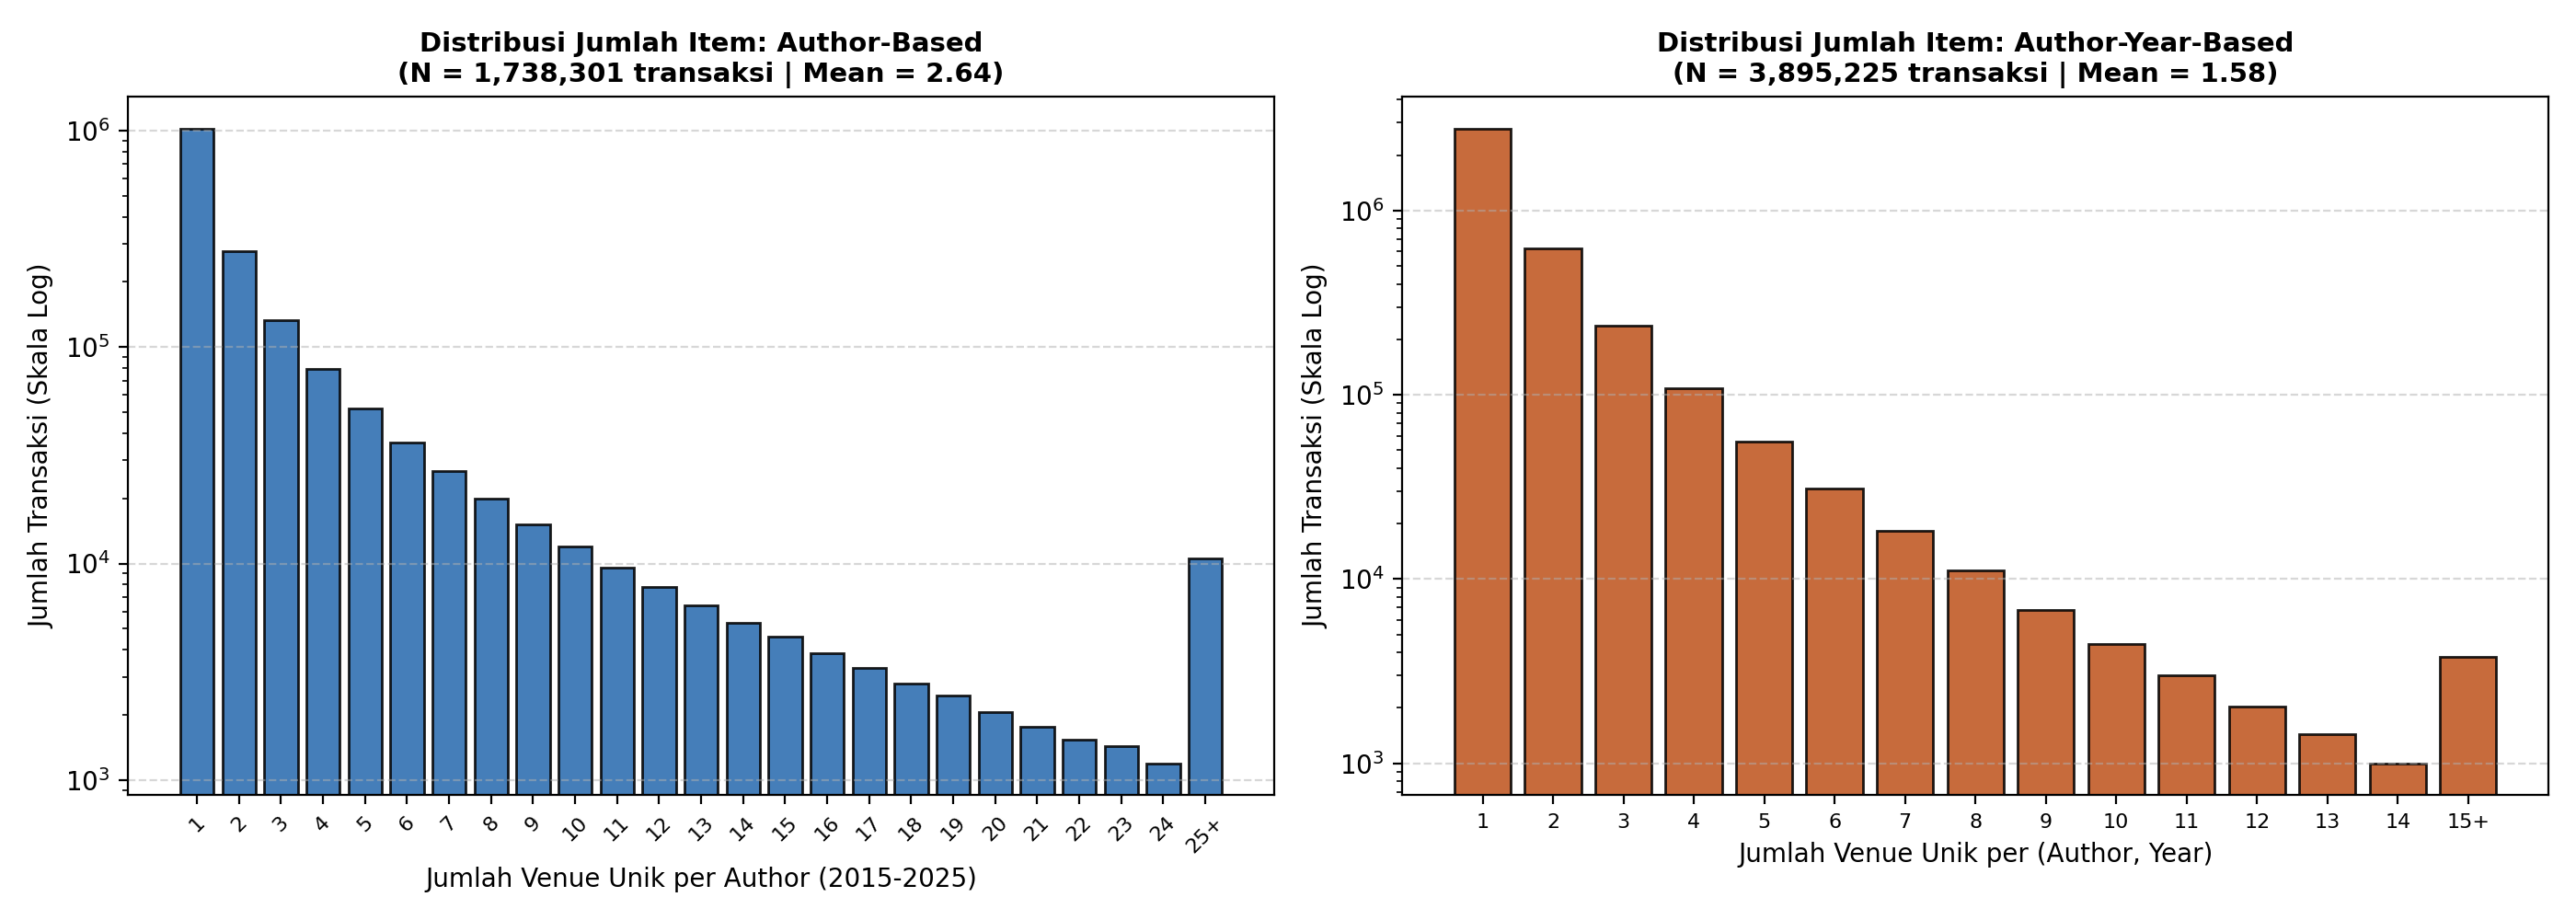

In [103]:
# T3-2 - Tampilkan visualisasi distribusi jumlah item per transaksi
display(Image(filename=str(OUTPUT_DIR / "task3_transaction_distribution.png")))

#### Analisis Task 3: Perbedaan, Kelebihan, dan Keterbatasan Kedua Representasi

1. **Perbedaan Empiris Author-Based vs Author-Year-Based (DBLP 2015–2025):**
   - **Jumlah transaksi:** *Author-Year-Based* menghasilkan **3.895.225 transaksi** (**2,24× lebih banyak** dibanding *Author-Based* yang berjumlah **1.738.301 transaksi**), karena setiap penulis yang aktif di beberapa tahun dipecah per tahun publikasi.
   - **Jumlah item unik:** Keduanya mencakup seluruh **4.232** `venue_key` unik yang sama.
   - **Panjang transaksi & kepadatan:** Keduanya sangat *sparse* dengan distribusi *heavy-tailed* (median sama-sama `1,0`), tetapi *Author-Based* memiliki rata-rata panjang item jauh lebih besar (**2,645** vs **1,576**; P95 **9** vs **4**; maksimum **341** vs **92**) dan kepadatan matriks hampir dua kali lipat (**0,0625%** vs **0,0372%**).
   - **Proporsi transaksi multi-item (`len >= 2`):** Pada *Author-Based*, **41,32%** transaksi (`718.194` author) memiliki $\ge 2$ konferensi dan **25,31%** memiliki $\ge 3$ konferensi. Sebaliknya, pada *Author-Year-Based*, **71,49%** transaksi (`2.784.636`) hanya berisi 1 konferensi dan hanya **28,51%** yang memiliki $\ge 2$ konferensi.

2. **Kelebihan dan Keterbatasan untuk Frequent Pattern Mining:**
   - **Author-Based:**
     - *Kelebihan:* Jauh lebih kaya informasi ko-kejadian (41,32% transaksi multi-item), mampu menangkap **afinitas komunitas riset jangka panjang**, dan dapat mendeteksi pasangan konferensi **bienial (dua tahunan)** yang tahun penyelenggaraannya berselang-seling — misalnya `ICCV` (tahun ganjil) dan `ECCV` (tahun genap)!
     - *Keterbatasan:* Menghilangkan konteks temporal (publikasi tahun 2015 dan 2025 dari penulis yang sama digabung menjadi satu transaksi sehingga pergeseran minat riset tidak tampak), serta memiliki *long-tail super-authors* (hingga 341 venue) yang memicu banyak kombinasi itemset.
   - **Author-Year-Based:**
     - *Kelebihan:* Mempertahankan dimensi waktu sehingga sangat ideal untuk **Temporal Association Analysis (Task E)** dan menangkap fokus publikasi simultan dalam satu siklus tahunan.
     - *Keterbatasan:* Tingginya dominasi transaksi 1-item (71,49%) menekan nilai *support* kombinasi $k \ge 2$ secara tajam dan secara struktural **tidak dapat menangkap pasangan konferensi bienial yang tidak berlangsung di tahun yang sama** (seperti `{ICCV, ECCV}`).

### Task 4 — Frequent Pattern Mining (Apriori & FP-Growth)

Menjalankan algoritma **Apriori** dan **FP-Growth** pada **Author-Based Transactional Database** ($N = 1.738.301$ transaksi) dengan empat nilai *minimum support*:
- **0,1%** (`0.001` $\rightarrow$ minimal `1.739` author unik)
- **0,5%** (`0.005` $\rightarrow$ minimal `8.692` author unik)
- **1,0%** (`0.010` $\rightarrow$ minimal `17.384` author unik)
- **2,0%** (`0.020` $\rightarrow$ minimal `34.767` author unik)

**Catatan akurasi matematis (*Zero-Approximation Projection*):**
Untuk menghindari alokasi matriks *dense* 7,36 GB (`1,74 juta × 4.232`) di internal `mlxtend`, setiap eksperimen menerapkan sifat *anti-monotonicity* (Prinsip Apriori) secara eksak: hanya kolom venue dengan frekuensi $\ge \lceil s \cdot N \rceil$ dan baris transaksi aktif yang diproses, dengan penyesuaian *threshold* eksak terhadap $N_{\text{total}} = 1.738.301$. Nilai *support* akhir dikembalikan persis terhadap seluruh $1.738.301$ author dan diverifikasi menghasilkan himpunan 100% identik antara Apriori dan FP-Growth (`max_support_diff = 0.0`).

In [104]:
# T4-1 - Eksekusi Apriori & FP-Growth pada min_support = [0.1%, 0.5%, 1%, 2%]
fpm_results, benchmark_df = run_fpm_and_benchmark(
    t3_res["X_author"],
    t3_res["unique_venues"],
    venue_display_map,
    min_supports=MIN_SUPPORTS,
    min_confidence=MIN_CONFIDENCE,
    output_dir=OUTPUT_DIR,
    save_artifacts=True,
)

print("=== Ringkasan Jumlah Frequent Itemsets per Ukuran (1-, 2-, 3-, >=4-itemsets) ===")
display(
    benchmark_df[[
        "min_support_pct", "min_count", "itemsets_fpgrowth",
        "n_1_itemsets", "n_2_itemsets", "n_3_itemsets", "n_4plus_itemsets"
    ]]
)

for s in MIN_SUPPORTS:
    pct = f"{s*100:.1f}%"
    fi = fpm_results[s]["fi_fp"]
    print(f"\n--- Top 10 Frequent Itemsets Keseluruhan (Min Support = {pct}, total={len(fi):,}) ---")
    display(fi.head(10)[["support", "count", "length", "itemsets_names", "itemsets_keys"]])

    fi_multi = fi[fi["length"] >= 2]
    print(f"--- Top 10 Kombinasi Konferensi / Multi-Itemsets k>=2 (Min Support = {pct}, total={len(fi_multi):,}) ---")
    if fi_multi.empty:
        print("Tidak ada kombinasi konferensi (k >= 2) yang memenuhi threshold support ini.")
    else:
        display(fi_multi.head(10)[["support", "count", "length", "itemsets_names", "itemsets_keys"]])


Eksperimen Min Support = 0.1% (min_count >= 1,739 dari 1,738,301 author)
[Proyeksi Eksak] 1,305,817 author aktif x 583 venue kandidat (4.61s)
  Itemsets: FP=1,352 | Apriori=1,352 | Identik=True (1-item=583, 2-item=375, 3-item=270, >=4-item=124)
  Rules (conf>=50%): FP=865 | Apriori=865
  Runtime: Apriori=14.9670s vs FP-Growth=55.0144s | Peak RAM: Apriori=62.13 MB vs FP-Growth=313.86 MB

Eksperimen Min Support = 0.5% (min_count >= 8,692 dari 1,738,301 author)
[Proyeksi Eksak] 678,348 author aktif x 67 venue kandidat (0.24s)
  Itemsets: FP=81 | Apriori=81 | Identik=True (1-item=67, 2-item=14, 3-item=0, >=4-item=0)
  Rules (conf>=50%): FP=3 | Apriori=3
  Runtime: Apriori=0.3187s vs FP-Growth=15.5552s | Peak RAM: Apriori=11.69 MB vs FP-Growth=55.53 MB

Eksperimen Min Support = 1.0% (min_count >= 17,384 dari 1,738,301 author)
[Proyeksi Eksak] 465,704 author aktif x 28 venue kandidat (0.07s)
  Itemsets: FP=28 | Apriori=28 | Identik=True (1-item=28, 2-item=0, 3-item=0, >=4-item=0)
  Rules (c

,min_support_pct,min_count,itemsets_fpgrowth,n_1_itemsets,n_2_itemsets,n_3_itemsets,n_4plus_itemsets
0,0.1%,1739,1352,583,375,270,124
1,0.5%,8692,81,67,14,0,0
2,1.0%,17384,28,28,0,0,0
3,2.0%,34767,7,7,0,0,0


,support,count,length,itemsets_names,itemsets_keys
0,0.027280,47421,1,{CVPR},{cvpr}
1,0.026513,46088,1,{AAAI},{aaai}
2,0.024835,43171,1,{NeurIPS},{nips}
3,0.024035,41780,1,{ICASSP},{icassp}
4,0.022615,39311,1,{EMBC},{embc}
5,0.021203,36857,1,{HCI},{hci}
6,0.020242,35187,1,{IGARSS},{igarss}
7,0.017870,31063,1,{ICLR},{iclr}
8,0.017198,29896,1,{CHI},{chi}
9,0.017052,29641,1,{IJCNN},{ijcnn}


,support,count,length,itemsets_names,itemsets_keys
33,0.008918,15503,2,"{ICLR, NeurIPS}","{iclr, nips}"
46,0.007948,13816,2,"{CVPR, ECCV}","{cvpr, eccv}"
49,0.007646,13291,2,"{ICML, NeurIPS}","{icml, nips}"
50,0.007603,13217,2,"{AAAI, NeurIPS}","{aaai, nips}"
53,0.007348,12773,2,"{CVPR, NeurIPS}","{cvpr, nips}"
55,0.007064,12280,2,"{AAAI, CVPR}","{aaai, cvpr}"
57,0.006853,11912,2,"{ACL, EMNLP}","{acl, emnlp}"
58,0.006593,11460,2,"{AAAI, IJCAI}","{aaai, ijcai}"
60,0.006343,11026,2,"{CVPR, ICCV}","{cvpr, iccv}"
62,0.006269,10898,2,"{GLOBECOM, ICC [icc]}","{globecom, icc}"


,support,count,length,itemsets_names,itemsets_keys
0,0.027280,47421,1,{CVPR},{cvpr}
1,0.026513,46088,1,{AAAI},{aaai}
2,0.024835,43171,1,{NeurIPS},{nips}
3,0.024035,41780,1,{ICASSP},{icassp}
4,0.022615,39311,1,{EMBC},{embc}
5,0.021203,36857,1,{HCI},{hci}
6,0.020242,35187,1,{IGARSS},{igarss}
7,0.017870,31063,1,{ICLR},{iclr}
8,0.017198,29896,1,{CHI},{chi}
9,0.017052,29641,1,{IJCNN},{ijcnn}


,support,count,length,itemsets_names,itemsets_keys
33,0.008918,15503,2,"{ICLR, NeurIPS}","{iclr, nips}"
46,0.007948,13816,2,"{CVPR, ECCV}","{cvpr, eccv}"
49,0.007646,13291,2,"{ICML, NeurIPS}","{icml, nips}"
50,0.007603,13217,2,"{AAAI, NeurIPS}","{aaai, nips}"
53,0.007348,12773,2,"{CVPR, NeurIPS}","{cvpr, nips}"
55,0.007064,12280,2,"{AAAI, CVPR}","{aaai, cvpr}"
57,0.006853,11912,2,"{ACL, EMNLP}","{acl, emnlp}"
58,0.006593,11460,2,"{AAAI, IJCAI}","{aaai, ijcai}"
60,0.006343,11026,2,"{CVPR, ICCV}","{cvpr, iccv}"
62,0.006269,10898,2,"{GLOBECOM, ICC [icc]}","{globecom, icc}"


,support,count,length,itemsets_names,itemsets_keys
0,0.027280,47421,1,{CVPR},{cvpr}
1,0.026513,46088,1,{AAAI},{aaai}
2,0.024835,43171,1,{NeurIPS},{nips}
3,0.024035,41780,1,{ICASSP},{icassp}
4,0.022615,39311,1,{EMBC},{embc}
5,0.021203,36857,1,{HCI},{hci}
6,0.020242,35187,1,{IGARSS},{igarss}
7,0.017870,31063,1,{ICLR},{iclr}
8,0.017198,29896,1,{CHI},{chi}
9,0.017052,29641,1,{IJCNN},{ijcnn}


,support,count,length,itemsets_names,itemsets_keys
0,0.027280,47421,1,{CVPR},{cvpr}
1,0.026513,46088,1,{AAAI},{aaai}
2,0.024835,43171,1,{NeurIPS},{nips}
3,0.024035,41780,1,{ICASSP},{icassp}
4,0.022615,39311,1,{EMBC},{embc}
5,0.021203,36857,1,{HCI},{hci}
6,0.020242,35187,1,{IGARSS},{igarss}


=== Top 15 Frequent 2-Itemsets (Min Support = 0.1%) ===

=== Top 15 Frequent 3-Itemsets (Min Support = 0.1%) ===


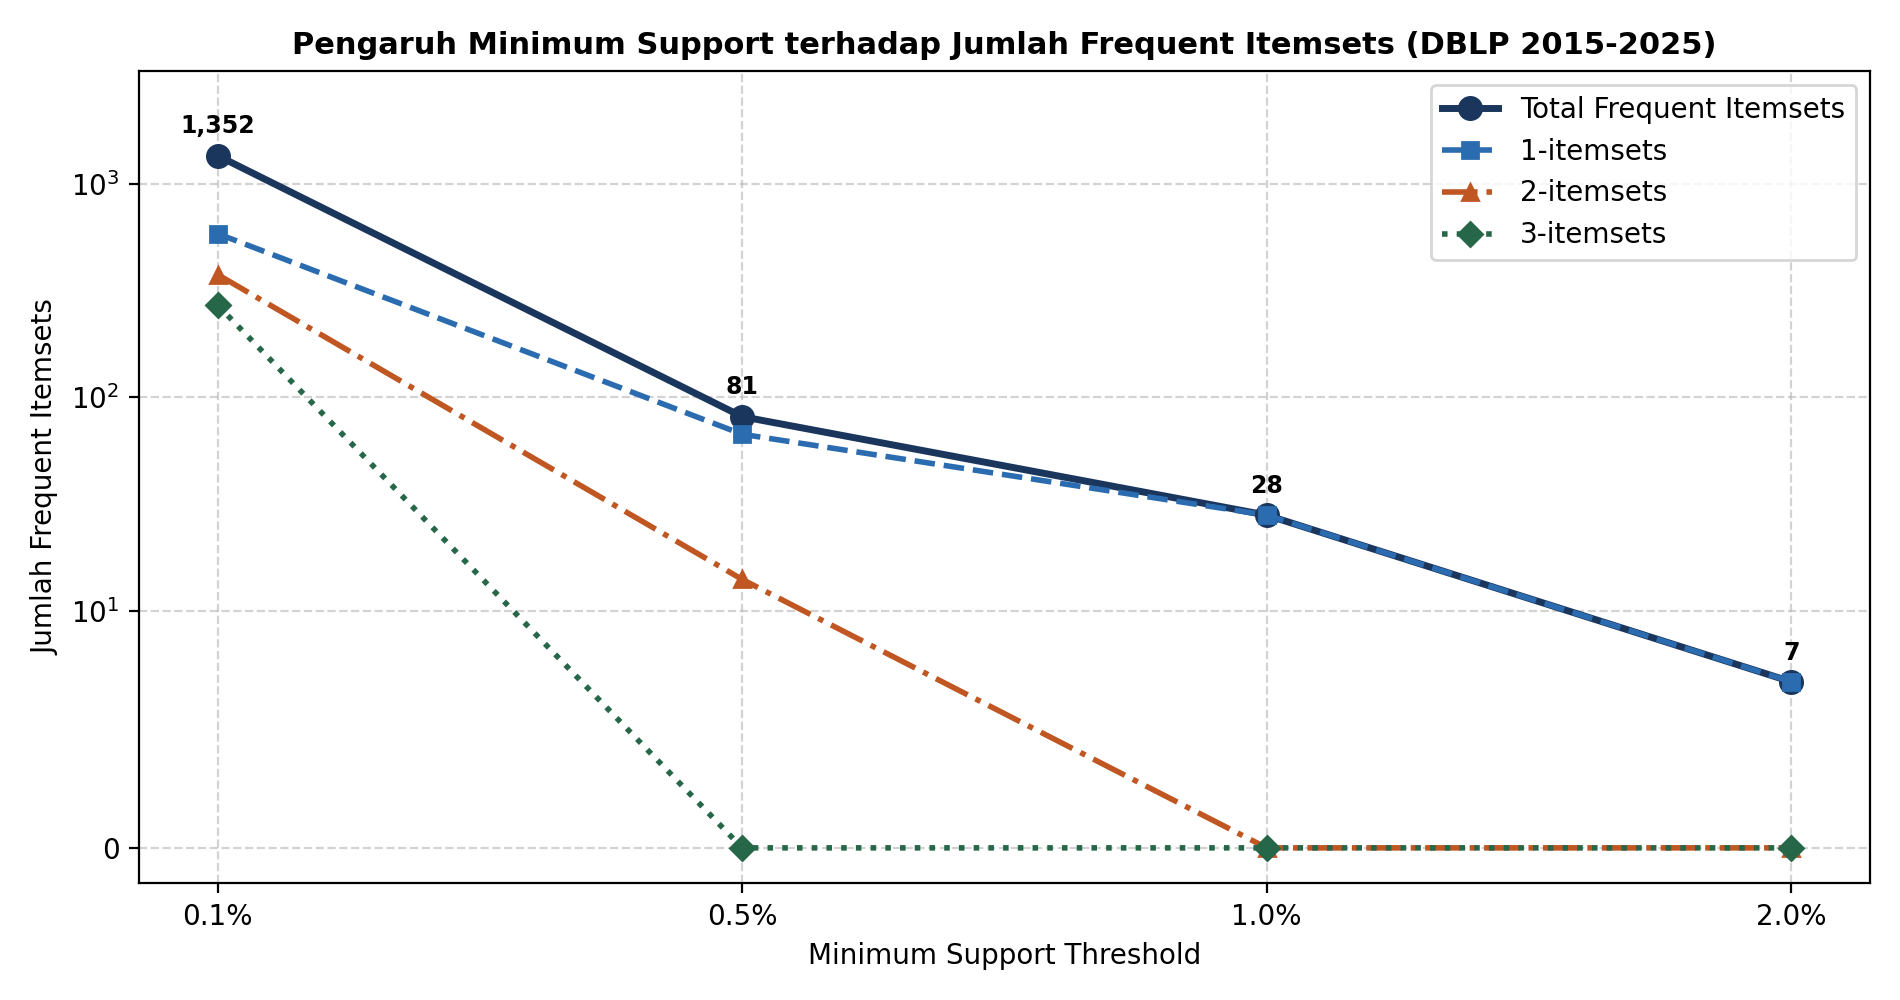

,support,count,itemsets_names,itemsets_keys
33,0.008918,15503,"{ICLR, NeurIPS}","{iclr, nips}"
46,0.007948,13816,"{CVPR, ECCV}","{cvpr, eccv}"
49,0.007646,13291,"{ICML, NeurIPS}","{icml, nips}"
50,0.007603,13217,"{AAAI, NeurIPS}","{aaai, nips}"
53,0.007348,12773,"{CVPR, NeurIPS}","{cvpr, nips}"
55,0.007064,12280,"{AAAI, CVPR}","{aaai, cvpr}"
57,0.006853,11912,"{ACL, EMNLP}","{acl, emnlp}"
58,0.006593,11460,"{AAAI, IJCAI}","{aaai, ijcai}"
60,0.006343,11026,"{CVPR, ICCV}","{cvpr, iccv}"
62,0.006269,10898,"{GLOBECOM, ICC [icc]}","{globecom, icc}"


,support,count,itemsets_names,itemsets_keys
87,0.004737,8235,"{ICLR, ICML, NeurIPS}","{iclr, icml, nips}"
131,0.003965,6892,"{CVPR, ECCV, ICCV}","{cvpr, eccv, iccv}"
136,0.003847,6688,"{AAAI, ICLR, NeurIPS}","{aaai, iclr, nips}"
144,0.003713,6454,"{CVPR, ICLR, NeurIPS}","{cvpr, iclr, nips}"
150,0.003627,6305,"{CVPR, ECCV, NeurIPS}","{cvpr, eccv, nips}"
151,0.003625,6302,"{AAAI, CVPR, NeurIPS}","{aaai, cvpr, nips}"
184,0.003294,5726,"{AAAI, CVPR, ECCV}","{aaai, cvpr, eccv}"
188,0.003266,5678,"{AAAI, ICML, NeurIPS}","{aaai, icml, nips}"
190,0.003262,5671,"{CVPR, ICCV, NeurIPS}","{cvpr, iccv, nips}"
196,0.003144,5466,"{ACL, EMNLP, NAACL-HLT}","{acl, emnlp, naacl}"


In [105]:
# T4-2 - Visualisasi sensitivitas minimum support & rincian Top 2-itemsets serta Top 3-itemsets (support 0.1%)
display(Image(filename=str(OUTPUT_DIR / "task4_support_sensitivity.png")))

fi_01 = fpm_results[0.001]["fi_fp"]
print("=== Top 15 Frequent 2-Itemsets (Min Support = 0.1%) ===")
display(fi_01[fi_01["length"] == 2].head(15)[["support", "count", "itemsets_names", "itemsets_keys"]])

print("\n=== Top 15 Frequent 3-Itemsets (Min Support = 0.1%) ===")
fi_3 = fi_01[fi_01["length"] == 3]
if fi_3.empty:
    print("Tidak ada 3-itemsets pada Min Support = 0.1%.")
else:
    display(fi_3.head(15)[["support", "count", "itemsets_names", "itemsets_keys"]])

#### Interpretasi Hasil Frequent Pattern Mining (Task 4)

1. **Pengaruh Perubahan Minimum Support terhadap Jumlah Frequent Itemsets:**
   - Penurunan *minimum support* memicu peningkatan jumlah *frequent itemsets* yang sangat tajam (non-linear):
     - **2,0% (`>= 34.767` author):** hanya **7** *1-itemsets* (`CVPR`, `AAAI`, `NeurIPS`, `ICASSP`, `EMBC`, `HCI`, `IGARSS`), **0** kombinasi multi-item.
     - **1,0% (`>= 17.384` author):** **28** *1-itemsets*, **0** kombinasi multi-item — bahkan pasangan konferensi terkuat pun belum mencapai 1% dari total 1,74 juta peneliti Ilmu Komputer.
     - **0,5% (`>= 8.692` author):** **81** itemsets (**67** *1-itemsets* + **14** *2-itemsets*, **0** *3-itemsets*). Pasangan konferensi inti mulai terlihat.
     - **0,1% (`>= 1.739` author):** melonjak menjadi **1.352** itemsets (**583** *1-itemsets*, **375** *2-itemsets*, **270** *3-itemsets*, dan **124** $\ge 4$-itemsets).
   - Pola ini menegaskan bahwa pada basis data bibliografi DBLP yang sangat *sparse* (`0,0625%`), pemilihan *minimum support* terlalu tinggi ($\ge 1\%$) akan menghilangkan seluruh pola ko-kejadian antar-konferensi.

2. **Kombinasi Konferensi Paling Sering Muncul Bersama & Maknanya:**
   - **Top 2-Itemsets:** Dipimpin oleh `{ICLR, NeurIPS}` (**15.503 author / 0,892%**), `{CVPR, ECCV}` (**13.816 / 0,795%**), `{ICML, NeurIPS}` (**13.291 / 0,765%**), `{AAAI, NeurIPS}` (**13.217 / 0,760%**), `{CVPR, NeurIPS}` (**12.773 / 0,735%**), `{AAAI, CVPR}` (**12.280 / 0,706%**), `{ACL, EMNLP}` (**11.912 / 0,685%**), `{AAAI, IJCAI}` (**11.460 / 0,659%**), `{CVPR, ICCV}` (**11.026 / 0,634%**), dan `{GLOBECOM, ICC [icc]}` (**10.898 / 0,627%** — rumpun IEEE Communications).
   - **Top 3-Itemsets:** Secara bersih mengungkap **"The Big Three"** di tiga subbidang terbesar Ilmu Komputer modern:
     1. *Machine Learning / Deep Learning:* `{ICLR, ICML, NeurIPS}` (**8.235 author / 0,474%**)
     2. *Computer Vision:* `{CVPR, ECCV, ICCV}` (**6.892 author / 0,397%**)
     3. *Natural Language Processing:* `{ACL, EMNLP, NAACL-HLT}` (**5.466 author / 0,314%**)
     4. Serta pola lintas-disiplin kuat antara Vision dan Deep Learning seperti `{CVPR, ICLR, NeurIPS}` (**6.454 author**) dan `{AAAI, ICLR, NeurIPS}` (**6.688 author**).

### Task 5 — Association Rule Mining (`min_confidence = 50%`)

Membangkitkan *association rules* dari *frequent itemsets* menggunakan ambang **minimum confidence 50% (`0.50`)**, menghitung **Support, Confidence, dan Lift**, serta mengidentifikasi **10 association rules dengan nilai Lift tertinggi**.

**Perbedaan Interpretasi Ketiga Metrik:**
- **Support($A \rightarrow B$) $= P(A \cup B)$:** Proporsi seluruh penulis di dataset ($N = 1.738.301$) yang memublikasikan paper di $A$ sekaligus $B$. Mengukur **skala / seberapa luas** pola tersebut secara global.
- **Confidence($A \rightarrow B$) $= P(B \mid A) = \frac{P(A \cup B)}{P(A)}$:** Peluang bersyarat bahwa penulis yang telah memublikasikan di $A$ juga memublikasikan di $B$. Mengukur **keandalan arah aturan** (asimetris: $P(B \mid A) \neq P(A \mid B)$).
- **Lift($A \rightarrow B$) $= \frac{P(A \cup B)}{P(A)P(B)} = \frac{\text{Confidence}(A \rightarrow B)}{\text{Support}(B)}$:** Rasio kekuatan asosiasi dibandingkan asumsi independensi. $\text{Lift} > 1$ berarti kemunculan $A$ secara positif meningkatkan peluang kemunculan $B$ sebesar $\text{Lift}\times$ lipat; $\text{Lift} = 1$ independen; $\text{Lift} < 1$ asosiasi negatif.

In [106]:
# T5-1 - Bangkitkan association rules (min_confidence = 50%), Top 10 Lift, Top 10 1-to-1, Top 10 Support, & korelasi
t5_res = analyze_association_rules(
    fpm_results,
    target_support=0.001,
    output_dir=OUTPUT_DIR,
    save_artifacts=True,
)

rules_df = t5_res["rules"]
print(f"Total Association Rules (Min Support=0.1%, Min Conf=50%): {len(rules_df):,}")

if not t5_res["top10_lift"].empty:
    print("\n=== Top 10 Association Rules Keseluruhan berdasarkan Lift Tertinggi ===")
    display(t5_res["top10_lift"][["rule_names", "rule_keys", "antecedent support", "consequent support", "support", "confidence", "lift"]])

    # Tampilkan juga Top 10 aturan 1-ke-1 (|A|=1, |B|=1) agar terlihat hubungan pasangan tunggal antar-domain
    rules_1to1 = rules_df[~rules_df["rule_keys"].str.contains(",")].head(10)
    print(f"\n=== Top 10 Association Rules Pasangan Tunggal (1 -> 1) berdasarkan Lift (dari {int((~rules_df['rule_keys'].str.contains(',')).sum())} aturan 1->1) ===")
    display(rules_1to1[["rule_names", "rule_keys", "support", "confidence", "lift"]])

    print("\n=== Top 10 Association Rules berdasarkan Support Tertinggi (Pembanding Support vs Lift) ===")
    display(t5_res["top10_support"][["rule_names", "rule_keys", "support", "confidence", "lift"]])

    print("\n=== Top 10 Association Rules berdasarkan Confidence Tertinggi ===")
    display(rules_df.sort_values(["confidence", "lift"], ascending=False).head(10)[["rule_names", "support", "confidence", "lift"]])

    print("\n=== Ringkasan Korelasi Support vs Lift ===")
    display(pd.DataFrame([t5_res["corr"]]))


TASK 5: ASSOCIATION RULE MINING (Min Support=0.1%, Min Confidence=50%)
Total association rules dihasilkan: 865

--- TOP 10 ASSOCIATION RULES BERDASARKAN LIFT TERTINGGI ---
                                  rule_names  support  confidence       lift
       {ICCV, ICML} -> {CVPR, ICLR, NeurIPS} 0.001010    0.552897 148.915546
       {AAAI, ECCV, ICLR} -> {ICCV, NeurIPS} 0.001014    0.560216 146.175949
{ACM Multimedia, CVPR, ECCV} -> {AAAI, ICCV} 0.001041    0.504319 144.830297
       {ECCV, ICML} -> {CVPR, ICLR, NeurIPS} 0.001069    0.519285 139.862534
       {AAAI, ICCV, ICLR} -> {ECCV, NeurIPS} 0.001014    0.620775 139.815132
       {ICCV, ICLR} -> {CVPR, ECCV, NeurIPS} 0.001462    0.501975 138.395426
       {AAAI, EMNLP, ICLR} -> {ACL, NeurIPS} 0.001065    0.580797 137.942340
       {AAAI, ACL, ICLR} -> {EMNLP, NeurIPS} 0.001065    0.502716 137.682618
       {CVPR, ECCV, ICLR} -> {ICCV, NeurIPS} 0.001462    0.527058 137.524044
{ACM Multimedia, CVPR, ICCV} -> {AAAI, ECCV} 0.001041    

,rule_names,rule_keys,antecedent support,consequent support,support,confidence,lift
0,"{ICCV, ICML} -> {CVPR, ICLR, NeurIPS}","{iccv, icml} -> {cvpr, iclr, nips}",0.001827,0.003713,0.001010,0.552897,148.915546
1,"{AAAI, ECCV, ICLR} -> {ICCV, NeurIPS}","{aaai, eccv, iclr} -> {iccv, nips}",0.001810,0.003832,0.001014,0.560216,146.175949
2,"{ACM Multimedia, CVPR, ECCV} -> {AAAI, ICCV}","{cvpr, eccv, mm} -> {aaai, iccv}",0.002065,0.003482,0.001041,0.504319,144.830297
3,"{ECCV, ICML} -> {CVPR, ICLR, NeurIPS}","{eccv, icml} -> {cvpr, iclr, nips}",0.002058,0.003713,0.001069,0.519285,139.862534
4,"{AAAI, ICCV, ICLR} -> {ECCV, NeurIPS}","{aaai, iccv, iclr} -> {eccv, nips}",0.001634,0.004440,0.001014,0.620775,139.815132
5,"{ICCV, ICLR} -> {CVPR, ECCV, NeurIPS}","{iccv, iclr} -> {cvpr, eccv, nips}",0.002913,0.003627,0.001462,0.501975,138.395426
6,"{AAAI, EMNLP, ICLR} -> {ACL, NeurIPS}","{aaai, emnlp, iclr} -> {acl, nips}",0.001833,0.004210,0.001065,0.580797,137.942340
7,"{AAAI, ACL, ICLR} -> {EMNLP, NeurIPS}","{aaai, acl, iclr} -> {emnlp, nips}",0.002118,0.003651,0.001065,0.502716,137.682618
8,"{CVPR, ECCV, ICLR} -> {ICCV, NeurIPS}","{cvpr, eccv, iclr} -> {iccv, nips}",0.002775,0.003832,0.001462,0.527058,137.524044
9,"{ACM Multimedia, CVPR, ICCV} -> {AAAI, ECCV}","{cvpr, iccv, mm} -> {aaai, eccv}",0.001868,0.004143,0.001041,0.557266,134.503758


,rule_names,rule_keys,support,confidence,lift
79,{ECOC} -> {OFC},{ecoc} -> {ofc},0.002051,0.712857,81.814392
340,{EACL} -> {EMNLP},{eacl} -> {emnlp},0.001614,0.571399,41.151107
405,{EACL} -> {ACL},{eacl} -> {acl},0.001668,0.590548,35.825718
410,{CoRL} -> {ICRA},{corl} -> {icra},0.001203,0.583264,35.555046
429,{SPAWC} -> {ICC [icc]},{spawc} -> {icc},0.001113,0.531173,34.661141
483,{Conference on Designing Interactive Systems} -> {CHI},{ACMdis} -> {chi},0.001822,0.558238,32.458706
509,{NAACL-HLT} -> {ACL},{naacl} -> {acl},0.004311,0.521539,31.639300
593,{UIST} -> {CHI},{uist} -> {chi},0.001468,0.507561,29.512083
698,{ICCV} -> {CVPR},{iccv} -> {cvpr},0.006343,0.695120,25.480874
730,{3DV} -> {CVPR},{3dim} -> {cvpr},0.001134,0.657438,24.099569


,rule_names,rule_keys,support,confidence,lift
809,{ECCV} -> {CVPR},{eccv} -> {cvpr},0.007948,0.586866,21.512617
758,{ICML} -> {NeurIPS},{icml} -> {nips},0.007646,0.576891,23.228807
698,{ICCV} -> {CVPR},{iccv} -> {cvpr},0.006343,0.695120,25.480874
356,"{ICLR, NeurIPS} -> {ICML}","{iclr, nips} -> {icml}",0.004737,0.531188,40.078293
428,"{ICML, NeurIPS} -> {ICLR}","{icml, nips} -> {iclr}",0.004737,0.619592,34.672689
521,"{ICLR, ICML} -> {NeurIPS}","{iclr, icml} -> {nips}",0.004737,0.780051,31.409133
509,{NAACL-HLT} -> {ACL},{naacl} -> {acl},0.004311,0.521539,31.639300
273,"{CVPR, ICCV} -> {ECCV}","{cvpr, iccv} -> {eccv}",0.003965,0.625068,46.153953
491,"{ECCV, ICCV} -> {CVPR}","{eccv, iccv} -> {cvpr}",0.003965,0.880092,32.261334
621,"{AAAI, NeurIPS} -> {ICLR}","{aaai, nips} -> {iclr}",0.003847,0.506015,28.316851


,rule_names,support,confidence,lift
417,"{ECCV, ICCV, ICLR, NeurIPS} -> {CVPR}",0.001462,0.956718,35.070202
418,"{AAAI, ECCV, ICCV, NeurIPS} -> {CVPR}",0.001466,0.955739,35.034309
421,"{AAAI, ECCV, ICCV, ICLR} -> {CVPR}",0.001139,0.953298,34.944833
424,"{AAAI, ACM Multimedia, ECCV, ICCV} -> {CVPR}",0.001041,0.950630,34.847041
427,"{ICCV, NeurIPS, WACV} -> {CVPR}",0.001033,0.946231,34.685774
430,"{BMVC, ECCV, ICCV} -> {CVPR}",0.001020,0.945096,34.644171
432,"{ECCV, ICCV, ICML} -> {CVPR}",0.001110,0.941895,34.526817
433,"{ACM Multimedia, ICCV, NeurIPS} -> {CVPR}",0.001179,0.941203,34.501486
434,"{ECCV, ICCV, NeurIPS} -> {CVPR}",0.002365,0.940948,34.492105
436,"{ECCV, ICCV, WACV} -> {CVPR}",0.001361,0.940358,34.470488


,pearson_support_lift,spearman_support_lift,spearman_p_value,spearman_consequent_support_lift,spearman_consequent_p_value
0,-0.153072,-0.140197,0.000035,-0.863304,1.599098e-258


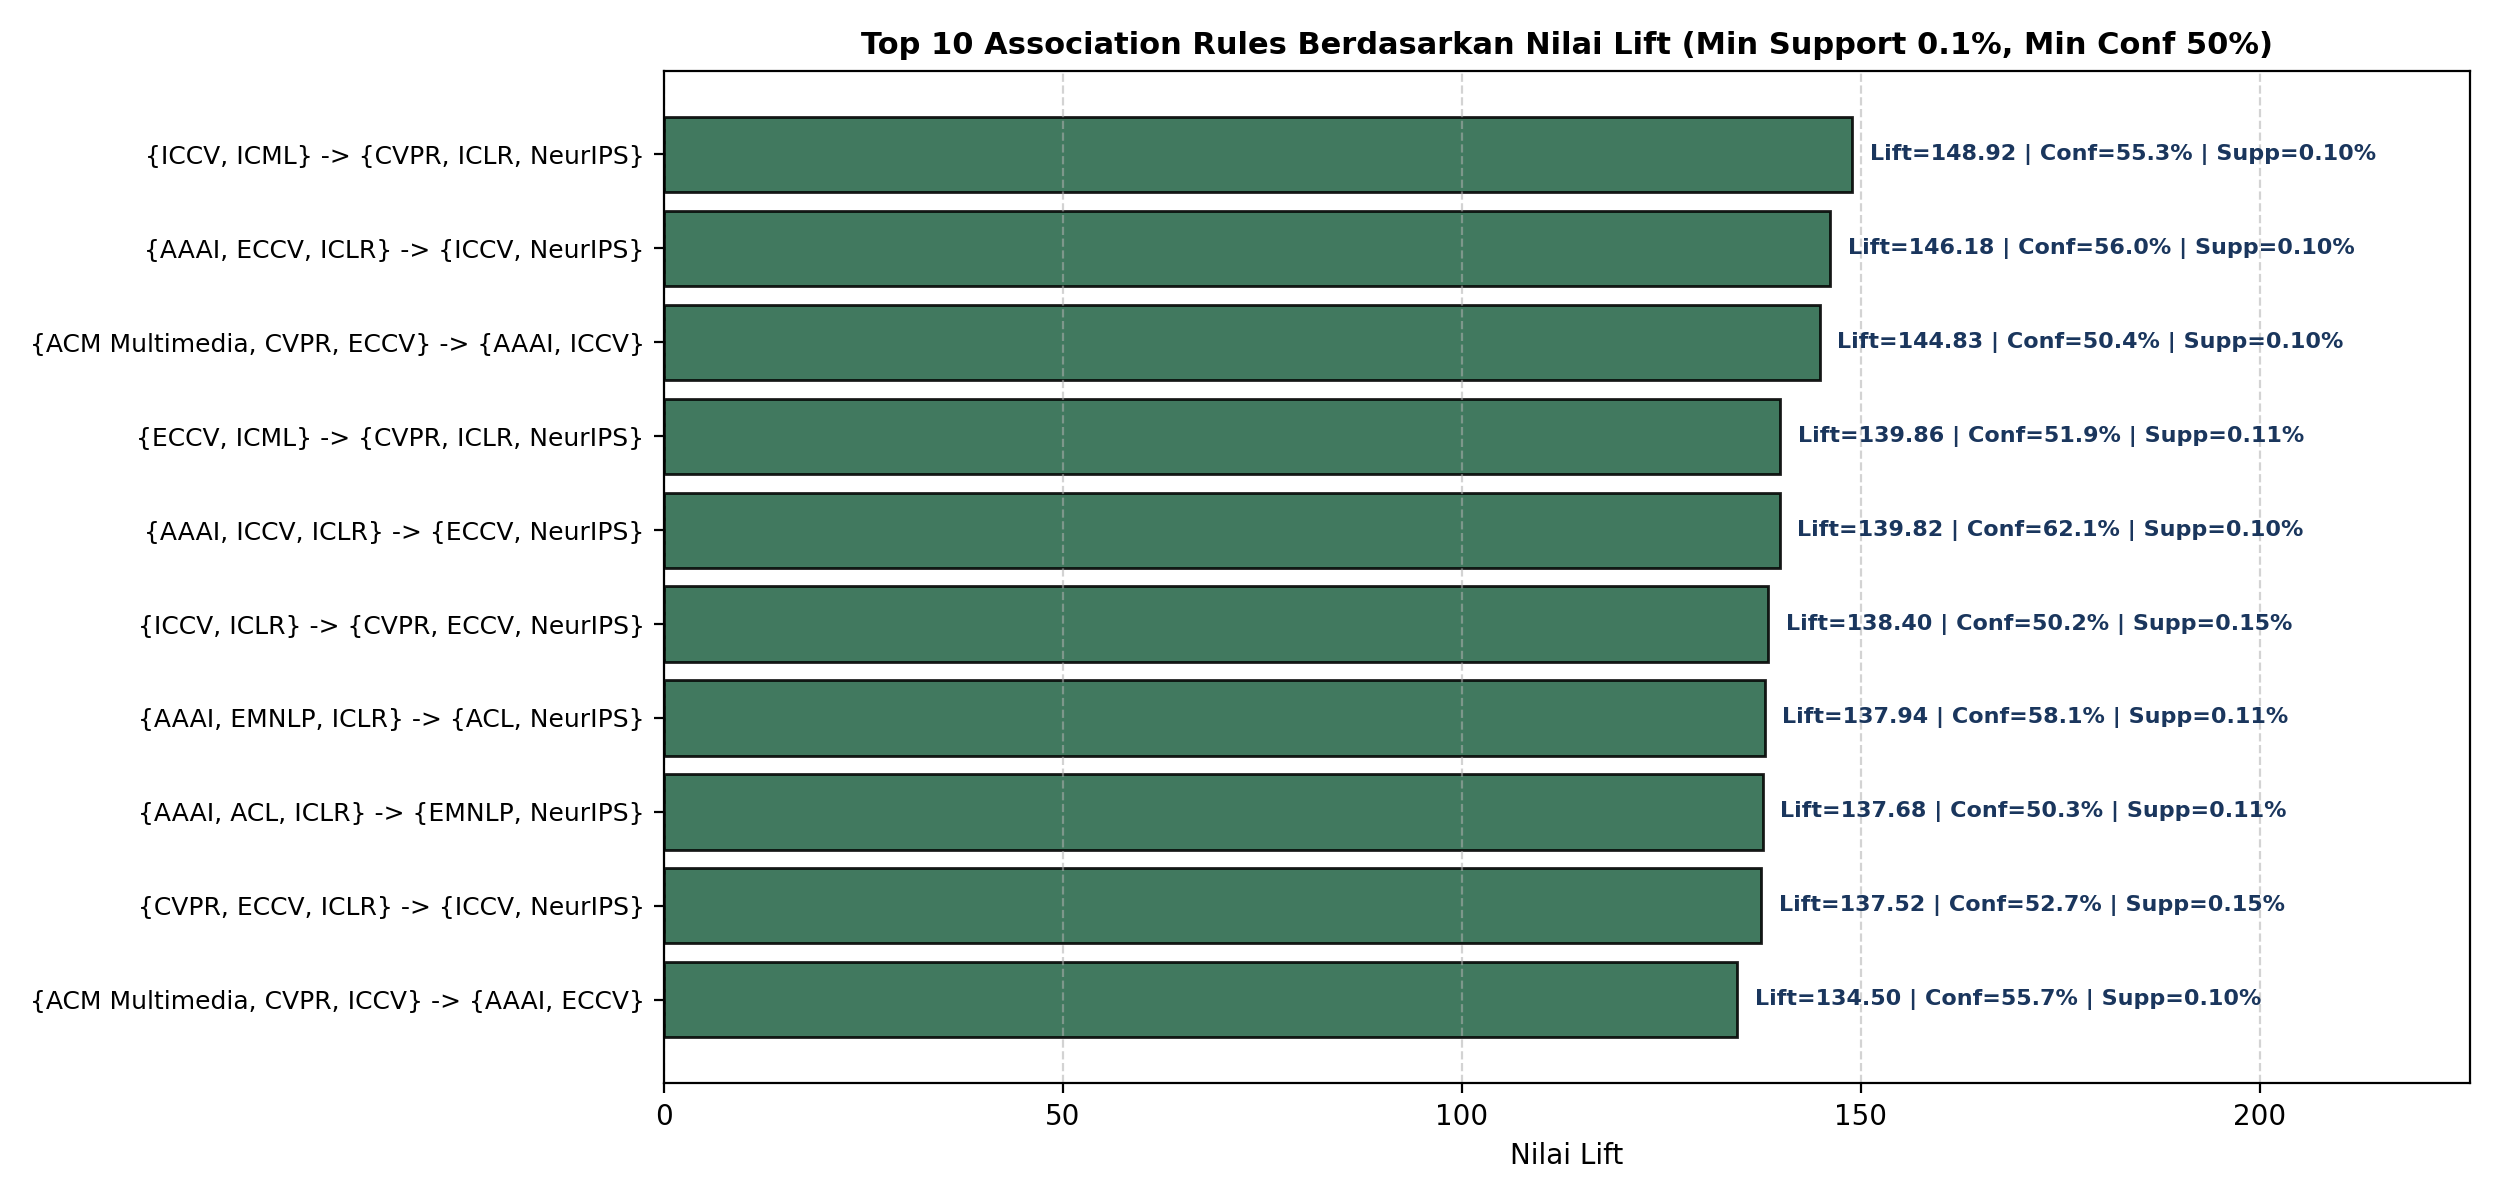

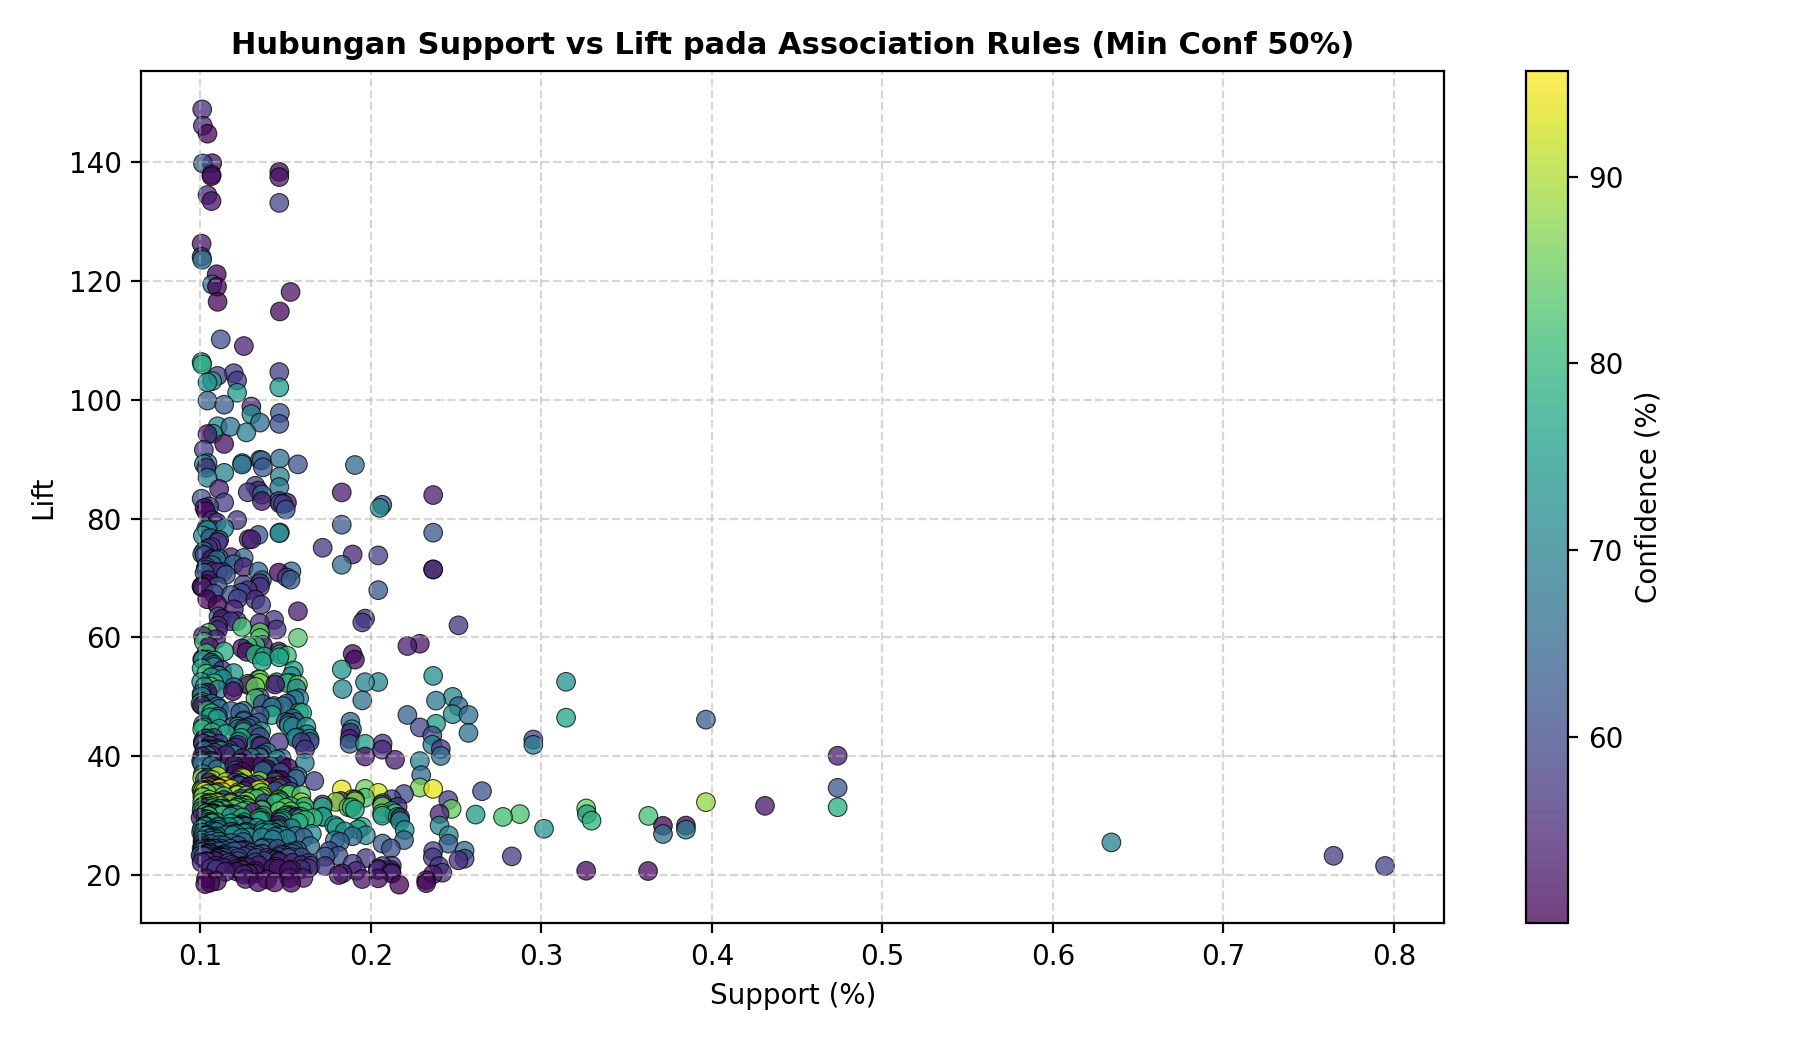

In [107]:
# T5-2 - Tampilkan grafik Top 10 Rules Lift & Scatter Plot Support vs Lift
if (OUTPUT_DIR / "task5_top10_rules_lift.png").is_file():
    display(Image(filename=str(OUTPUT_DIR / "task5_top10_rules_lift.png")))
if (OUTPUT_DIR / "task5_support_vs_lift.png").is_file():
    display(Image(filename=str(OUTPUT_DIR / "task5_support_vs_lift.png")))

#### Analisis & Interpretasi Association Rule Mining (Task 5)

1. **Hubungan Asosiasi Antar-Konferensi yang Paling Menarik (865 Rules pada Support 0,1%, Conf $\ge$ 50%):**
   - **Top Lift Keseluruhan (aturan multi-konferensi):** Peringkat #1 adalah `{ICCV, ICML} -> {CVPR, ICLR, NeurIPS}` (**Lift = 148,92**, Conf = **55,29%**, Support = **0,101%**), diikuti `{AAAI, ECCV, ICLR} -> {ICCV, NeurIPS}` (**Lift = 146,18**) dan `{ACM Multimedia, CVPR, ECCV} -> {AAAI, ICCV}` (**Lift = 144,83**). Peneliti yang sudah menjembatani dua venue elite lintas subbidang (Vision + ML) hampir 149× lebih mungkin memublikasikan di seluruh paket venue flagship AI/Vision dibandingkan peluang acak.
   - **Top Lift Pasangan Tunggal (1 $\rightarrow$ 1):** Mengungkap komunitas spesialis lintas bidang Ilmu Komputer di luar AI:
     - *Komunikasi Optik:* `{ECOC} -> {OFC}` (**Lift = 81,81**, Conf = **71,29%**, Support = **0,205%**) — dua konferensi utama dunia di bidang komunikasi serat optik.
     - *NLP:* `{EACL} -> {EMNLP}` (**Lift = 41,15**), `{EACL} -> {ACL}` (**Lift = 35,83**), `{NAACL-HLT} -> {ACL}` (**Lift = 31,64**).
     - *Robotika:* `{CoRL} -> {ICRA}` (**Lift = 35,56**, Conf = **58,33%**).
     - *Komunikasi Nirkabel:* `{SPAWC} -> {ICC [icc]}` (**Lift = 34,66**, Conf = **53,12%**).
     - *Interaksi Manusia-Komputer (HCI):* `{Conference on Designing Interactive Systems} -> {CHI}` (**Lift = 32,46**) dan `{UIST} -> {CHI}` (**Lift = 29,51**).
   - **Top Confidence:** `{ECCV, ICCV, ICLR, NeurIPS} -> {CVPR}` mencapai **Confidence = 95,67%** (hampir pasti penulis dengan rekam jejak keempat venue tersebut juga memublikasikan di `CVPR`).

2. **Apakah Konferensi dengan Support Tinggi Selalu Menghasilkan Lift Tinggi?**
   - **TIDAK.** Uji korelasi pada seluruh 865 rules membuktikan korelasi **negatif** yang signifikan secara statistik:
     - Korelasi Pearson (*Support vs Lift*) = **$-0{,}1531$**; Spearman = **$-0{,}1402$** ($p = 3{,}51 \times 10^{-5}$).
     - Korelasi Spearman (*Consequent Support vs Lift*) = **$-0{,}8633$** ($p = 1{,}60 \times 10^{-258}$ — sangat kuat!).
   - **Bukti Empiris Langsung:** Rule ber-support tertinggi `{ECCV} -> {CVPR}` (Support **0,795%**) memiliki Lift **21,51** karena `CVPR` sendiri adalah konferensi dengan basis penulis terbesar (2,73% populasi), sehingga penyebut $\text{Support}(B)$ membesar. Sebaliknya, `{ECOC} -> {OFC}` (Support hampir 4× lebih kecil: **0,205%**) mencapai Lift **81,81**, dan `{ICCV, ICML} -> {CVPR, ICLR, NeurIPS}` (Support **0,101%**) mencapai Lift **148,92**.

3. **Pola Publikasi Antar-Konferensi yang Teridentifikasi:**
   - **Pola *Feeder-to-Flagship* (Asimetris):** Peneliti pada konferensi yang lebih selektif/spesialis atau regional cenderung juga hadir di konferensi *flagship* utama rumpunnya (misalnya `ICCV/ECCV/3DV/BMVC -> CVPR`, `ICML/AISTATS/UAI -> NeurIPS`, `EACL/NAACL-HLT -> ACL`, `UIST/DIS -> CHI`, `CoRL -> ICRA`), namun tidak selalu berlaku sebaliknya karena konferensi *flagship* menarik audiens lebih luas.
   - **Kluster Domain Terpisah vs Konvergensi Deep Learning:** Bidang seperti Komunikasi Optik (`ECOC`/`OFC`), Wireless (`SPAWC`/`ICC`/`GLOBECOM`), Robotika (`CoRL`/`ICRA`), dan HCI (`UIST`/`DIS`/`CHI`) membentuk ekosistem asosiasi yang sangat eksklusif, sementara bidang AI, Vision, Multimedia, dan NLP menunjukkan konvergensi lintas-konferensi yang tinggi berpusat pada `NeurIPS`, `ICLR`, `CVPR`, dan `AAAI`.

### Task 6 — Algorithm Performance Comparison (Apriori vs FP-Growth)

Membandingkan performa **Apriori** (`mlxtend`, `low_memory=True`) dan **FP-Growth** (`mlxtend`) pada basis data transaksi dan parameter *minimum support* yang persis sama (`0.1%`, `0.5%`, `1%`, `2%`) berdasarkan:
1. Jumlah *frequent itemsets* yang dihasilkan kedua algoritma (beserta uji kesamaan eksak).
2. Jumlah *association rules* yang dihasilkan (`min_confidence = 50%`).
3. Waktu eksekusi (*runtime* dalam detik) dan puncak penggunaan memori (*peak RAM* via `tracemalloc`).

PASS - Apriori dan FP-Growth menghasilkan himpunan frequent itemsets & jumlah rules 100% identik di semua threshold.


,min_support_pct,itemsets_apriori,itemsets_fpgrowth,itemsets_identical,max_support_diff,rules_apriori_conf50,rules_fpgrowth_conf50,runtime_apriori_s,runtime_fpgrowth_s,speedup_ap_over_fp,peak_ram_apriori_mb,peak_ram_fpgrowth_mb
0,0.1%,1352,1352,True,0.0,865,865,14.9670,55.0144,0.27,62.13,313.86
1,0.5%,81,81,True,0.0,3,3,0.3187,15.5552,0.02,11.69,55.53
2,1.0%,28,28,True,0.0,0,0,0.0669,9.4527,0.01,6.43,14.42
3,2.0%,7,7,True,0.0,0,0,0.0094,4.3210,0.00,2.66,0.07


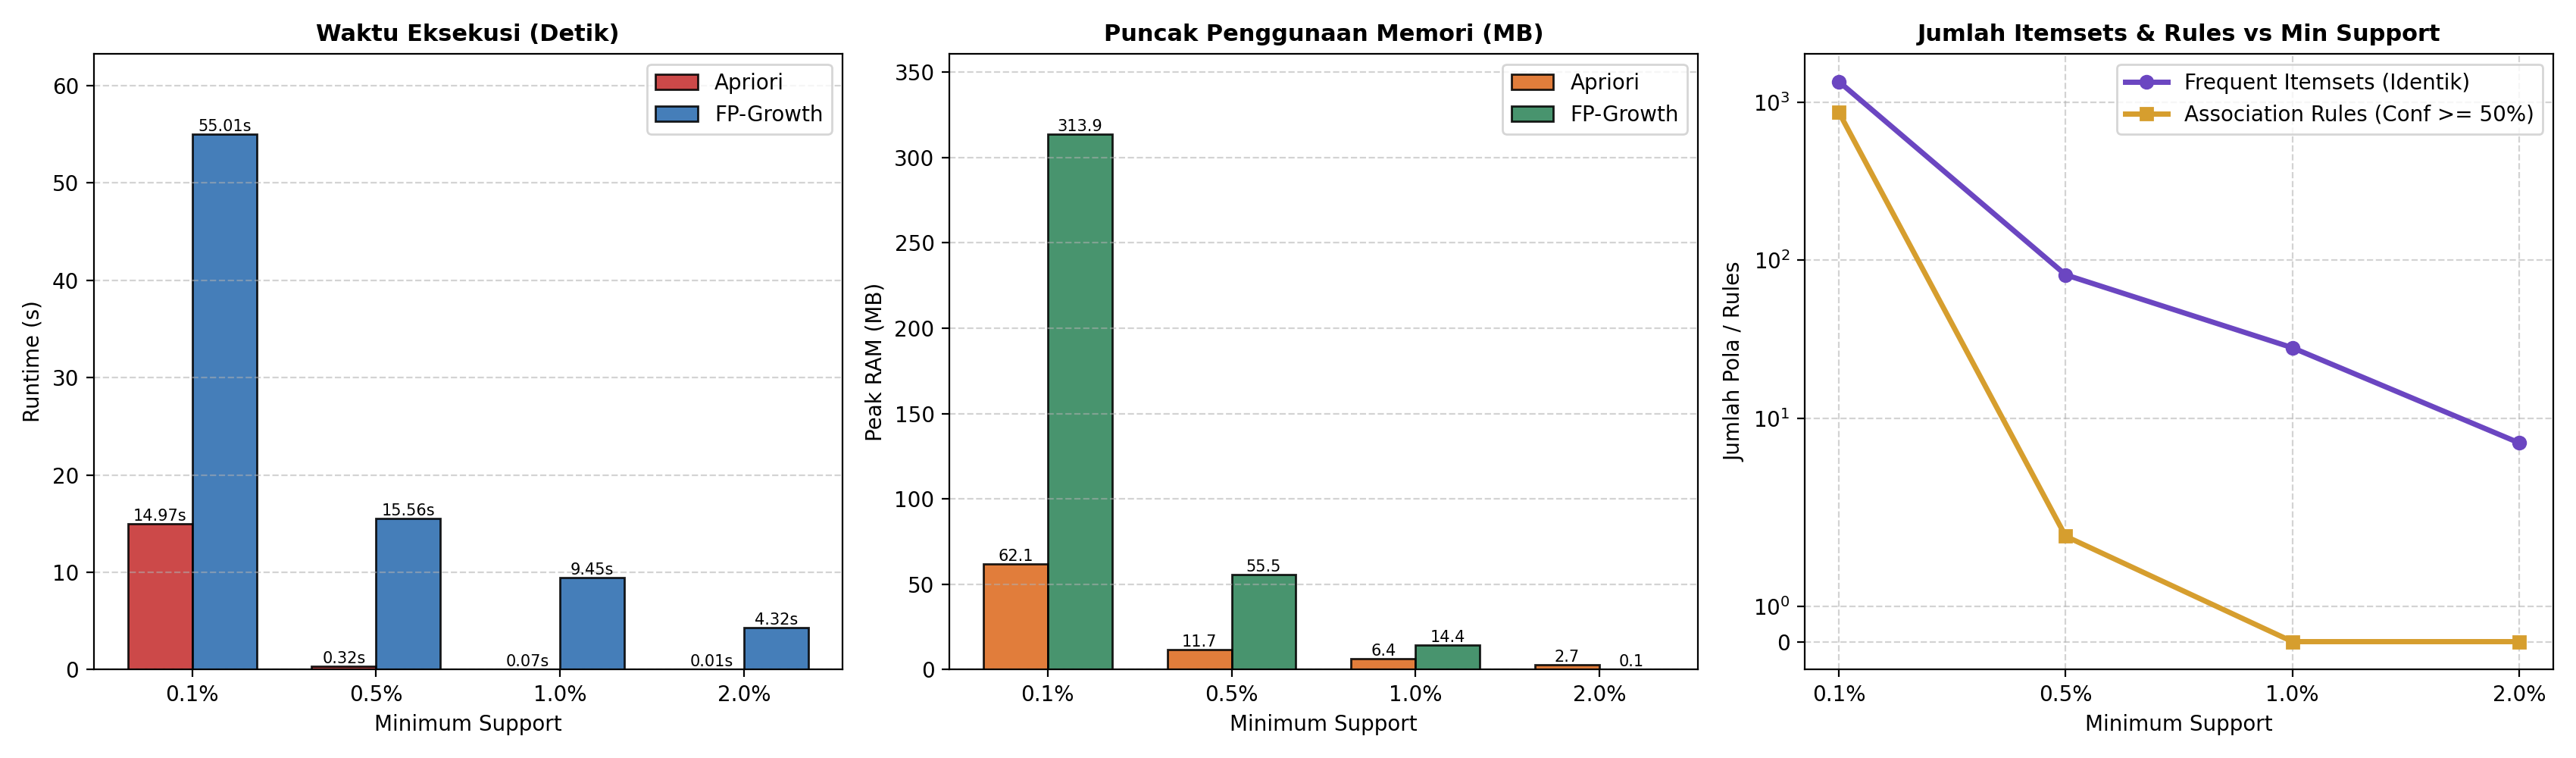

In [108]:
# T6-1 - Tabel komparasi performa lengkap, asersi kesamaan eksak, dan grafik visualisasi
cols_t6 = [
    "min_support_pct",
    "itemsets_apriori",
    "itemsets_fpgrowth",
    "itemsets_identical",
    "max_support_diff",
    "rules_apriori_conf50",
    "rules_fpgrowth_conf50",
    "runtime_apriori_s",
    "runtime_fpgrowth_s",
    "speedup_ap_over_fp",
    "peak_ram_apriori_mb",
    "peak_ram_fpgrowth_mb",
]
display(benchmark_df[cols_t6])

assert benchmark_df["itemsets_identical"].all(), "Apriori dan FP-Growth menghasilkan itemset berbeda!"
assert (benchmark_df["rules_apriori_conf50"] == benchmark_df["rules_fpgrowth_conf50"]).all(), "Jumlah rules berbeda!"
print("PASS - Apriori dan FP-Growth menghasilkan himpunan frequent itemsets & jumlah rules 100% identik di semua threshold.")

display(Image(filename=str(OUTPUT_DIR / "task6_algorithm_performance_comparison.png")))

#### Jawaban Pertanyaan Evaluasi Perbandingan Algoritma (Task 6)

1. **Bagaimana perubahan minimum support memengaruhi performa kedua algoritma?**
   - Menurunkan *minimum support* dari **2,0%** ke **0,1%** meningkatkan beban komputasi kedua algoritma secara drastis karena jumlah transaksi aktif melonjak dari `229.968` menjadi `1.305.817` author dan jumlah venue kandidat bertambah dari `7` menjadi `583`, sehingga total *frequent itemsets* naik dari `7` menjadi `1.352` (dan *association rules* dari `0` menjadi `865`).
   - **Apriori (`low_memory=True`):** Waktu eksekusi meningkat dari **0,009 detik** (2,0%) $\rightarrow$ **0,067 detik** (1,0%) $\rightarrow$ **0,319 detik** (0,5%) $\rightarrow$ **14,967 detik** (0,1%), dengan puncak memori naik dari **2,66 MB** menjadi **62,13 MB**. Lonjakan terbesar terjadi saat berpindah dari `0,5%` ke `0,1%` karena mulai muncul 769 kombinasi multi-item ($k \ge 2$) yang memicu iterasi pembentukan kandidat $C_k$.
   - **FP-Growth (`mlxtend`):** Waktu eksekusi meningkat dari **4,321 detik** (2,0%) $\rightarrow$ **9,453 detik** (1,0%) $\rightarrow$ **15,555 detik** (0,5%) $\rightarrow$ **55,014 detik** (0,1%), dengan puncak memori naik dari **0,07 MB** menjadi **313,86 MB**. Sebagian besar waktu FP-Growth pada `mlxtend` terserap oleh pembangunan pohon `FPTree` berbasis objek Python murni di seluruh `230 ribu` hingga `1,31 juta` transaksi aktif.

2. **Apakah kedua algoritma menghasilkan frequent itemsets yang sama?**
   - **Ya, 100% identik.** Pada seluruh empat *threshold* (`0,1%`, `0,5%`, `1,0%`, `2,0%`), `itemsets_identical = True`, selisih support maksimum `max_support_diff = 0.0`, serta jumlah *association rules* identik persis (`865`, `3`, `0`, `0`). Ini memvalidasi secara empiris bahwa Apriori dan FP-Growth adalah dua algoritma *exact frequent pattern mining* yang ekuivalen secara matematis dan hanya berbeda pada strategi pencarian serta struktur datanya.

3. **Berdasarkan hasil eksperimen, algoritma mana yang lebih sesuai untuk dataset DBLP yang digunakan? Jelaskan alasan Anda.**
   - **Pada rentang parameter eksperimen proyek ini (`min_support = 0,1% – 2,0%` dengan pustaka Python `mlxtend`), Apriori (`low_memory=True`) terbukti lebih unggul dan lebih sesuai secara empiris:**
     1. **Lebih cepat di seluruh threshold:** Apriori **3,7× lebih cepat** di `0,1%` (`14,97s` vs `55,01s`), **49× lebih cepat** di `0,5%` (`0,32s` vs `15,56s`), **141× lebih cepat** di `1,0%` (`0,07s` vs `9,45s`), dan **460× lebih cepat** di `2,0%` (`0,01s` vs `4,32s`).
     2. **Lebih hemat memori pada support rendah:** Di `0,1%`, puncak memori Apriori hanya **62,13 MB** dibandingkan FP-Growth yang mencapai **313,86 MB** (~5× lebih hemat).
     3. **Penjelasan teknis (Karakteristik DBLP + Implementasi):** Dataset *Author-Based* DBLP memiliki **1,74 juta baris transaksi** tetapi **sangat *sparse* (`0,0625%`)** dengan itemset yang relatif dangkal (0 pasangan pada `1–2%`, 14 pasangan pada `0,5%`, dan 1.352 total itemset pada `0,1%`). Pada rezim *ultra-sparse* dengan kandidat $C_k$ terbatas, Apriori (`low_memory=True`) memanfaatkan operasi vektorisasi NumPy berbahasa C yang sangat cepat tanpa mengalami ledakan kombinatorial, sedangkan FP-Growth di `mlxtend` harus melakukan iterasi *loop* Python murni dan mengalokasikan ratusan ribu objek `FPNode` untuk 1,3 juta transaksi.
   - **Catatan skalabilitas teoretis:** Apabila eksperimen diperluas ke ambang *minimum support* yang jauh lebih ekstrem (misalnya `< 0,02%` untuk menambang *workshop* kecil) atau pada dataset yang sangat *dense* di mana jumlah kandidat $C_k$ meledak secara eksponensial, keunggulan asimtotik **FP-Growth** (terutama implementasi terkompilasi C/C++) dalam menghindari *candidate generation* akan menjadi krusial.

### Pertanyaan Kesimpulan (Bagian H)

1. Konferensi apa yang memiliki popularitas publikasi tertinggi berdasarkan dataset DBLP? 
2. Apakah konferensi yang paling populer juga memiliki asosiasi paling kuat dengan 
konferensi lain? 
3. Kombinasi konferensi apa yang paling sering muncul bersama dalam riwayat publikasi 
author? 
4. Association rules apa yang menghasilkan lift tertinggi? Apa makna dari rule tersebut? 
5. Apakah terdapat perbedaan pola yang ditemukan pada Author-Based dan Author-Year
Based Transactional Database? 
6. Algoritma mana yang memberikan performa terbaik pada dataset yang digunakan? 
7. Apa pengetahuan atau insight utama yang berhasil diperoleh dari penerapan Frequent 
Pattern Mining dan Association Rule Mining terhadap dataset DBLP? 